# Entrenamiento de Red Neuronal Enfocado a Salud Mental en Estudiantes Universitarios

Estudiantes:
- Nicoll Quesada
- Daniel Hurtado
- Santiago Lozano

### Pregunta de Investigación:

- ¿En qué medida variables como el comportamiento del estudiante, estabilidad financiera, ambiente social y desempeño académico pueden utilizarse para realizar una detección temprana de la necesidad de ayuda psicológica?

## Importación de los datos

Basado en los avances mencionados durante la etapa 1, la base de datos original obtenida de https://data.mendeley.com/datasets/bytb22nf7m/1 requería un par de cambios para ser utilizada como una base de datos para aprendizaje profundo. Esta nueva base de datos cuenta con etiquetas de depresión la cuales son las que se utilizarán para entrenar el modelo. La importación de los datos se encuentra a continuación:

In [1]:
# ============================================================
# IMPORTACIÓN DE LOS DATOS
# Elegir el origen del archivo CSV:
#   "local" -> lee el CSV que está en la misma carpeta del notebook
#   "drive" -> (Google Colab) monta Google Drive y lee el CSV desde allí
#   "subir" -> (Google Colab) abre el selector para subir el archivo
# ============================================================
import io
import os
import pandas as pd

FUENTE_DATOS = "local"   # "local" | "drive" | "subir"

NOMBRE_ARCHIVO = "data_with_depression_risk (1).csv"
RUTA_LOCAL = NOMBRE_ARCHIVO                                   # relativa a la carpeta del notebook
RUTA_DRIVE = f"/content/drive/MyDrive/{NOMBRE_ARCHIVO}"       # ajustar si el archivo está en otra carpeta de Drive

if FUENTE_DATOS == "local":
    if not os.path.exists(RUTA_LOCAL):
        raise FileNotFoundError(f'No se encontró "{RUTA_LOCAL}" en {os.getcwd()}')
    df = pd.read_csv(RUTA_LOCAL)
    print(f'Archivo local "{RUTA_LOCAL}" cargado.')

elif FUENTE_DATOS == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    df = pd.read_csv(RUTA_DRIVE)
    print(f'Archivo de Drive "{RUTA_DRIVE}" cargado.')

elif FUENTE_DATOS == "subir":
    from google.colab import files
    print("Por favor, selecciona el archivo CSV que deseas cargar:")
    uploaded = files.upload()
    for fn in uploaded.keys():
        print(f'Archivo "{fn}" cargado. Leyendo...')
        df = pd.read_csv(io.StringIO(uploaded[fn].decode("utf-8")))

else:
    raise ValueError('FUENTE_DATOS debe ser "local", "drive" o "subir"')

print("DataFrame cargado exitosamente. Las primeras 5 filas son:")
print(df.head())

Archivo local "data_with_depression_risk (1).csv" cargado.
DataFrame cargado exitosamente. Las primeras 5 filas son:
   1. Year of birth:  2. Gender  \
0               2001          1   
1               1999          1   
2               2002          1   
3               2001          2   
4               1999          1   

   3. What is the socio-economic status of your home?  \
0                                                  4    
1                                                  2    
2                                                  5    
3                                                  5    
4                                                  4    

   4. According to your culture, people, or physical features, you are or are recognized as:  \
0                                                  6                                           
1                                                  1                                           
2                                        

Se observa que los nombres de columnas son muy extensos por lo que se abrevia el nombre de columna y se genera un diccionario con las preguntas originales.

In [2]:
# ============================================================
# Abreviación de los nombres de columnas del DataFrame `df`
# y creación de un diccionario de variables en español
# (asume que `df` ya fue cargado en la celda anterior)
# ============================================================
import re
import pandas as pd

# ------------------------------------------------------------
# 1. Diccionario de preguntas: número -> (nombre corto, descripción en español)
# ------------------------------------------------------------
diccionario_preguntas = {
    "1":   ("anio_nac",       "Año de nacimiento"),
    "2":   ("genero",         "Género"),
    "3":   ("estrato",        "Estrato socioeconómico del hogar"),
    "4":   ("etnia",          "Reconocimiento según cultura, pueblo o rasgos físicos"),
    "5.1": ("educ_padre",     "Años de educación del padre"),
    "5.2": ("educ_madre",     "Años de educación de la madre"),
    "6":   ("satisf_vida",    "Satisfacción general con todos los aspectos de la vida"),
    "7":   ("felicidad_ayer", "Qué tan feliz se sintió ayer"),
    "8":   ("risa_ayer",      "Cuánto se rió ayer"),
    "9":   ("aprendio_ayer",  "Si aprendió cosas nuevas o interesantes ayer"),
}

# Preguntas 16.x -> Escala de Estrés Percibido (PSS-10)
# Escala 0 a 4: 0 = nunca, 1 = casi nunca, 2 = a veces, 3 = bastante seguido, 4 = muy seguido
# Referencia: durante el último mes
items_pss = [
    "Se ha sentido afectado por algo que ocurrió inesperadamente",
    "Se ha sentido incapaz de controlar las cosas importantes de su vida",
    "Se ha sentido nervioso o estresado",
    "Se ha sentido seguro de su capacidad para manejar sus problemas personales",
    "Ha sentido que las cosas le iban bien",
    "Ha sentido que no podía afrontar todas las cosas que tenía que hacer",
    "Ha podido controlar las dificultades de su vida",
    "Ha sentido que tenía todo bajo control",
    "Se ha enojado por cosas que estaban fuera de su control",
    "Ha sentido que las dificultades se acumulaban tanto que no podía superarlas",
]
for i, texto in enumerate(items_pss, start=1):
    diccionario_preguntas[f"16.{i}"] = (f"pss_{i}", f"Estrés (último mes): {texto}")

# Preguntas 17.x -> Escala de ansiedad GAD-7
# Escala 0 a 3: 0 = nunca, 1 = varios días, 2 = más de la mitad de los días, 3 = casi todos los días
# Referencia: últimas dos semanas
items_gad = [
    "Sentirse nervioso, ansioso o con los nervios de punta",
    "No poder dejar de preocuparse o controlar la preocupación",
    "Preocuparse demasiado por diferentes cosas",
    "Dificultad para relajarse",
    "Estar tan inquieto que es difícil quedarse quieto",
    "Molestarse o irritarse fácilmente",
    "Sentir miedo, como si algo terrible fuera a pasar",
]
for i, texto in enumerate(items_gad, start=1):
    diccionario_preguntas[f"17.{i}"] = (f"gad_{i}", f"Ansiedad (últimas 2 semanas): {texto}")


# ------------------------------------------------------------
# 2. Función que devuelve (nombre corto, descripción) para cada columna
# ------------------------------------------------------------
def abreviar(columna):
    col = columna.strip()

    # Variable objetivo
    if col.lower().startswith("riesgo"):
        return "riesgo_dep", "Riesgo de depresión (variable objetivo: 0 = no, 1 = sí)"

    # Extrae el número de la pregunta al inicio (ej: "5.1", "16.10", "7")
    coincidencia = re.match(r"^(\d+(?:\.\d+)?)", col)
    if coincidencia:
        num = coincidencia.group(1)
        if num in diccionario_preguntas:
            return diccionario_preguntas[num]
        # Preguntas que no están en el diccionario (ej. 10 a 15):
        # se les asigna un nombre genérico para completar luego a mano
        return "p" + num.replace(".", "_"), f"Pregunta {num} (pendiente de traducir)"

    # Respaldo: columna sin número -> minúsculas, sin símbolos, máx. 20 caracteres
    return re.sub(r"\W+", "_", col.lower()).strip("_")[:20], "Sin descripción"


# ------------------------------------------------------------
# 3. Construir el mapeo y el diccionario de variables
# ------------------------------------------------------------
resultados = [abreviar(col) for col in df.columns]
mapa_columnas = {orig: corto for orig, (corto, _) in zip(df.columns, resultados)}

diccionario_variables = pd.DataFrame(resultados, columns=["nombre_corto", "descripcion"])

# Verificar que no haya nombres repetidos después de abreviar
duplicados = diccionario_variables["nombre_corto"][
    diccionario_variables["nombre_corto"].duplicated()
].tolist()
if duplicados:
    print("⚠️ Atención: nombres duplicados tras abreviar:", duplicados)

# ------------------------------------------------------------
# 4. Renombrar las columnas del DataFrame
# ------------------------------------------------------------
df = df.rename(columns=mapa_columnas)

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------
pd.set_option("display.max_colwidth", 100)
print("Diccionario de variables:")
display(diccionario_variables)
print("\nPrimeras filas con los nuevos nombres:")
display(df.head())

Diccionario de variables:


,nombre_corto,descripcion
0,anio_nac,Año de nacimiento
1,genero,Género
2,estrato,Estrato socioeconómico del hogar
3,etnia,"Reconocimiento según cultura, pueblo o rasgos físicos"
4,educ_padre,Años de educación del padre
5,educ_madre,Años de educación de la madre
6,satisf_vida,Satisfacción general con todos los aspectos de la vida
7,felicidad_ayer,Qué tan feliz se sintió ayer
8,risa_ayer,Cuánto se rió ayer
9,aprendio_ayer,Si aprendió cosas nuevas o interesantes ayer



Primeras filas con los nuevos nombres:


,anio_nac,genero,estrato,etnia,educ_padre,educ_madre,satisf_vida,felicidad_ayer,risa_ayer,aprendio_ayer,...,pss_9,pss_10,gad_1,gad_2,gad_3,gad_4,gad_5,gad_6,gad_7,riesgo_dep
0,2001,1,4,6,25.0,25.0,7,5,5,5,...,3,1,1,0,0,0,3,0,3,0
1,1999,1,2,1,NaN,NaN,8,4,8,3,...,3,2,0,3,1,1,0,1,1,1
2,2002,1,5,6,16.0,16.0,10,9,10,7,...,1,2,1,2,1,2,1,0,1,0
3,2001,2,5,6,20.0,16.0,10,8,10,10,...,2,1,0,0,1,0,0,1,0,0
4,1999,1,4,5,NaN,NaN,8,6,7,3,...,2,1,1,0,0,0,0,0,1,1


## Análsis Exploratorio de Datos

In [3]:
print(f"El DataFrame tiene {df.shape[0]} filas y {df.shape[1]} columnas.")

El DataFrame tiene 2992 filas y 34 columnas.


In [4]:
print('Conteo de valores faltantes por columna:')
print(df.isnull().sum())

Conteo de valores faltantes por columna:
anio_nac             0
genero               0
estrato              0
etnia                0
educ_padre         954
educ_madre        1059
satisf_vida          0
felicidad_ayer       0
risa_ayer            0
aprendio_ayer        0
p10                  0
p11                  0
p12                  0
p13                  0
p14                  0
p15                  0
pss_1                0
pss_2                0
pss_3                0
pss_4                0
pss_5                0
pss_6                0
pss_7                0
pss_8                0
pss_9                0
pss_10               0
gad_1                0
gad_2                0
gad_3                0
gad_4                0
gad_5                0
gad_6                0
gad_7                0
riesgo_dep           0
dtype: int64


Se observa que dos de las columnas tienen valores faltantes. Sin embargo, al ser las columnas de años de educación de los padres se puede decir que estos faltantes son datos MNAR que no se pueden inferir. Adicionalmente al ser más de 30% de la columna los datos que son faltantes se justifica más borrar la columna.

In [5]:
df = df.drop(columns=['educ_padre', 'educ_madre'])
print("Columnas 'educ_padre' y 'educ_madre' eliminadas.")
print(f"El DataFrame ahora tiene {df.shape[1]} columnas.")

Columnas 'educ_padre' y 'educ_madre' eliminadas.
El DataFrame ahora tiene 32 columnas.


Se observó tambien que las cateogrias dentro de la columna etnia pertenecen a una codificacion simple de distintas etnias, esto se corrige usando one hot encoding. Esto agrega 6 columnas con las disitntas etnias como valores binarios.

In [6]:
# Códigos de la pregunta 4 (etnia) con su etiqueta en español
etiquetas_etnia = {1: "indigena", 2: "gitano", 3: "raizal",
                   4: "palenquero", 5: "afrocolombiano", 6: "ninguno"}

# Cambiar los códigos por etiquetas y aplicar one-hot encoding (0/1)
dummies_etnia = pd.get_dummies(df["etnia"].map(etiquetas_etnia), prefix="etnia", dtype=int)

# Garantizar las 6 columnas aunque alguna categoría no aparezca en los datos
dummies_etnia = dummies_etnia.reindex(columns=[f"etnia_{v}" for v in etiquetas_etnia.values()], fill_value=0)

# Unir al DataFrame y eliminar la columna original
df = pd.concat([df.drop(columns="etnia"), dummies_etnia], axis=1)
display(df.filter(like="etnia_").head())


,etnia_indigena,etnia_gitano,etnia_raizal,etnia_palenquero,etnia_afrocolombiano,etnia_ninguno
0,0,0,0,0,0,1
1,1,0,0,0,0,0
2,0,0,0,0,0,1
3,0,0,0,0,0,1
4,0,0,0,0,1,0


## Preparación de los datos para entrenamiento

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separar características (X) y variable objetivo (y)
X = df.drop('riesgo_dep', axis=1)
y = df['riesgo_dep']

# 2. Asegurar que las variables binarias sean 0 o 1
# Transformar 'genero' (si está presente y tiene valores 1 y 2) a (0, 1)
if 'genero' in X.columns and X['genero'].isin([1, 2]).all():
    X['genero'] = X['genero'].map({1: 0, 2: 1})
    print("Columna 'genero' transformada: 1 -> 0, 2 -> 1.")
elif 'genero' in X.columns and not X['genero'].isin([0, 1]).all():
    print("Advertencia: La columna 'genero' no contiene solo 1s y 2s, o ya está en 0s y 1s. No se aplicó transformación automática.")
elif 'genero' in X.columns and X['genero'].isin([0, 1]).all():
    print("La columna 'genero' ya está en formato binario (0 y 1).")

# 3. Dividir los datos en conjuntos de entrenamiento y prueba (80/20) PRIMERO
# Usamos stratify=y para asegurar que la proporción de las clases de 'riesgo_dep' sea similar en ambos conjuntos.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Normalizar variables con 'gran escala numérica' DESPUÉS DEL SPLIT
# Identificamos 'anio_nac' y 'estrato' como candidatos principales.
# Las columnas 'etnia_...' ya son 0/1.
# Las columnas pss_X y gad_X tienen escalas pequeñas (0-4 y 0-3).
# Las columnas satisf_vida, felicidad_ayer, risa_ayer, aprendio_ayer, y p10-p15
# también se asumen de escalas pequeñas.

cols_to_normalize = ['anio_nac', 'estrato']

# Filtrar solo las columnas que realmente existen en X_train (y X_test)
cols_to_normalize = [col for col in cols_to_normalize if col in X_train.columns]

if cols_to_normalize:
    scaler = StandardScaler()
    # Ajustar scaler solo con datos de entrenamiento y transformar ambos conjuntos
    X_train[cols_to_normalize] = scaler.fit_transform(X_train[cols_to_normalize])
    X_test[cols_to_normalize] = scaler.transform(X_test[cols_to_normalize])
    print(f"Columnas normalizadas con StandardScaler: {cols_to_normalize}")
else:
    print("No se encontraron columnas para normalizar con StandardScaler según los criterios definidos.")

print(f"\nForma de X_train: {X_train.shape}")
print(f"Forma de X_test: {X_test.shape}")
print(f"Forma de y_train: {y_train.shape}")
print(f"Forma de y_test: {y_test.shape}")

print("\nConteo de valores de la variable objetivo en los conjuntos:")
print("y_train:\n", y_train.value_counts(normalize=True))
print("y_test:\n", y_test.value_counts(normalize=True))

# Mostrar primeras filas de X_train para confirmar preprocesamiento
print("\nPrimeras filas de X_train después del preprocesamiento:")
print(X_train.head())

Columna 'genero' transformada: 1 -> 0, 2 -> 1.
Columnas normalizadas con StandardScaler: ['anio_nac', 'estrato']

Forma de X_train: (2393, 36)
Forma de X_test: (599, 36)
Forma de y_train: (2393,)
Forma de y_test: (599,)

Conteo de valores de la variable objetivo en los conjuntos:
y_train:
 riesgo_dep
0    0.642708
1    0.357292
Name: proportion, dtype: float64
y_test:
 riesgo_dep
0    0.642738
1    0.357262
Name: proportion, dtype: float64

Primeras filas de X_train después del preprocesamiento:
      anio_nac  genero   estrato  satisf_vida  felicidad_ayer  risa_ayer  \
126   -0.02481       0 -1.134140            6               3          6   
463    0.64603       1 -1.134140            7               6          5   
364   -0.02481       0  0.922957            7               7          7   
2255   0.64603       0  0.237258           10               8          9   
1507   0.31061       0 -1.819839            4               5          3   

      aprendio_ayer  p10  p11  p12  ...  g

### Definición única de los conjuntos (numpy y tensores)

Todas las representaciones de los conjuntos de entrenamiento, validación y prueba se definen **una sola vez** aquí. Las secciones siguientes (Keras y PyTorch) reutilizan estas variables sin volver a convertirlas:

| Variable | Tipo | Uso |
|---|---|---|
| `X_train`, `X_test` | DataFrame | Modelos Keras |
| `y_train`, `y_test` | numpy | Keras y métricas de sklearn |
| `X_train_tensor`, `y_train_tensor` | tensor | Conjunto de entrenamiento completo |
| `X_train_exp`, `y_train_exp` | tensor | Entrenamiento de los experimentos (80 % de `X_train`) |
| `X_val`, `y_val` | tensor | Validación fija de los experimentos (20 % de `X_train`) |
| `X_test_tensor`, `y_test_tensor` | tensor | Evaluación final en prueba |

Las etiquetas en tensor tienen forma `(N, 1)` y tipo `float32`, que es lo que espera la pérdida BCE.

In [8]:
# ============================================================
# DEFINICIÓN ÚNICA DE LOS CONJUNTOS
# Todas las secciones posteriores reutilizan estas variables;
# no se vuelven a convertir ni a dividir en ninguna otra celda.
# ============================================================
import numpy as np
import torch

# ------------------------------------------------------------
# 1. Variable objetivo como numpy (Keras y métricas de sklearn)
#    X_train / X_test se mantienen como DataFrames.
# ------------------------------------------------------------
y_train = np.asarray(y_train).astype(np.int64)
y_test = np.asarray(y_test).astype(np.int64)

# ------------------------------------------------------------
# 2. Tensores de PyTorch del conjunto de entrenamiento y de prueba
#    Etiquetas en float32 con forma (N, 1) -> formato de la pérdida BCE
# ------------------------------------------------------------
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# ------------------------------------------------------------
# 3. Split FIJO entrenamiento / validación (80/20 de X_train)
#    Se usa el mismo en todos los experimentos para que sean comparables.
# ------------------------------------------------------------
VALIDATION_SPLIT = 0.20

generador_split = torch.Generator().manual_seed(42)
indices = torch.randperm(len(X_train_tensor), generator=generador_split)

n_val = int(len(X_train_tensor) * VALIDATION_SPLIT)
val_indices = indices[:n_val]
train_indices = indices[n_val:]

X_train_exp = X_train_tensor[train_indices]
y_train_exp = y_train_tensor[train_indices]

X_val = X_train_tensor[val_indices]
y_val = y_train_tensor[val_indices]

input_size = X_train_tensor.shape[1]

print(f"X_train_exp: {tuple(X_train_exp.shape)} | y_train_exp: {tuple(y_train_exp.shape)}")
print(f"X_val:       {tuple(X_val.shape)} | y_val:       {tuple(y_val.shape)}")
print(f"X_test:      {tuple(X_test_tensor.shape)} | y_test:      {tuple(y_test_tensor.shape)}")
print(f"Número de variables de entrada (input_size): {input_size}")


X_train_exp: (1915, 36) | y_train_exp: (1915, 1)
X_val:       (478, 36) | y_val:       (478, 1)
X_test:      (599, 36) | y_test:      (599, 1)
Número de variables de entrada (input_size): 36


## Pruebas de entrenamiento

Para las pruebas de entrenamiento se va a realizar primero un entrenamiento con un perceptron para utilizar este modelo como el modelo Baseline sobre el cual se va a intentar mejorar y optimizar.

### Modelo Baseline

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import classification_report

# X_train / X_test (DataFrames) y y_train / y_test (numpy) vienen de la
# sección "Preparación de los datos para entrenamiento".

# Definir el modelo perceptrón (una sola capa densa con activación sigmoide para clasificación binaria)
model = Sequential([
    Dense(1, activation='sigmoid', input_shape=(X_train.shape[1],))
])

# Compilar el modelo
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Entrenando el modelo perceptrón...")

# Entrenar el modelo
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2, verbose=0)

print("Modelo entrenado. Evaluando...")

# Evaluar el modelo en el conjunto de prueba
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecisión del modelo en el conjunto de prueba: {accuracy:.4f}")

# Predecir clases en el conjunto de prueba
y_pred_proba = model.predict(X_test, verbose=0)
y_pred = (y_pred_proba > 0.5).astype(int)

# Imprimir el reporte de clasificación
print("\nReporte de clasificación del modelo perceptrón:")
print(classification_report(y_test, y_pred))

2026-11-07 21:16:06.268541: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


/opt/anaconda3/envs/analitica_Datos/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entrenando el modelo perceptrón...


Modelo entrenado. Evaluando...

Precisión del modelo en el conjunto de prueba: 0.7479



Reporte de clasificación del modelo perceptrón:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       385
           1       0.66      0.59      0.63       214

    accuracy                           0.75       599
   macro avg       0.73      0.71      0.72       599
weighted avg       0.74      0.75      0.74       599



Se observa que al implementar un perceptron se observa un accuracy del 80% sobre el conjunto de prueba. A partir de aqui se va a construir una red neuronal que tiene como objetivo mejorar este resultado sin disminuir este desempeño.

### Contrucción de una red neuronal básica

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD

# Definir el modelo de red neuronal
# El número de entradas debe ser igual al número de columnas en X_train
model_nn = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)), # Capa oculta con 32 neuronas
    Dense(1, activation='sigmoid') # Capa de salida para clasificación binaria (0 o 1)
])

# Definir el optimizador SGD con la tasa de aprendizaje especificada
sgd_optimizer = SGD(learning_rate=0.01)

# Compilar el modelo
model_nn.compile(optimizer=sgd_optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Mostrar un resumen del modelo
print("Resumen de la Red Neuronal:")
model_nn.summary()

print("\nLa red neuronal está construida y compilada. Ahora puedes proceder a entrenarla.")

Resumen de la Red Neuronal:


/opt/anaconda3/envs/analitica_Datos/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 32)             │         1,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)


La red neuronal está construida y compilada. Ahora puedes proceder a entrenarla.


Entrenando la red neuronal...


Entrenamiento completado.



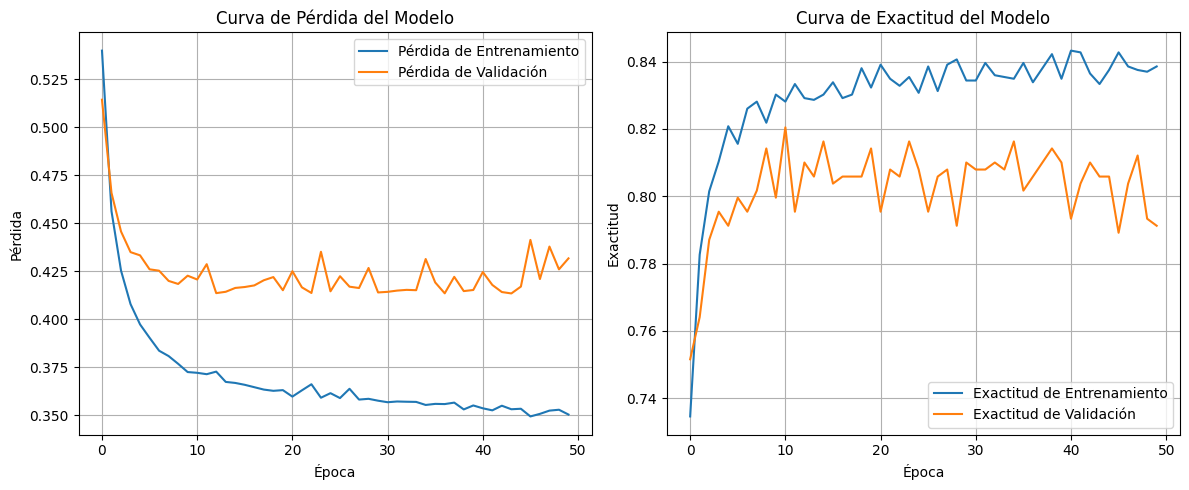


Evaluando la red neuronal en el conjunto de prueba...
Precisión en el conjunto de prueba: 0.8063

Reporte de Clasificación de la Red Neuronal:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       385
           1       0.77      0.65      0.71       214

    accuracy                           0.81       599
   macro avg       0.80      0.77      0.78       599
weighted avg       0.80      0.81      0.80       599



In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Entrenar el modelo y capturar el historial
print("Entrenando la red neuronal...")
history = model_nn.fit(x=X_train, y=y_train, epochs=50, verbose=0, validation_split=0.2)
print("Entrenamiento completado.\n")

# 1. Graficar las curvas de pérdida y exactitud
plt.figure(figsize=(12, 5))

# Curva de Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de Validación')
plt.title('Curva de Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

# Curva de Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Exactitud de Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Exactitud de Validación')
plt.title('Curva de Exactitud del Modelo')
plt.xlabel('Época')
plt.ylabel('Exactitud')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 2. Mostrar el reporte de clasificación final en el conjunto de prueba
print("\nEvaluando la red neuronal en el conjunto de prueba...")
loss_nn, accuracy_nn = model_nn.evaluate(X_test, y_test, verbose=0)
print(f"Precisión en el conjunto de prueba: {accuracy_nn:.4f}")

# Predecir clases en el conjunto de prueba
y_pred_proba_nn = model_nn.predict(X_test, verbose=0)
y_pred_nn = (y_pred_proba_nn > 0.5).astype(int)

# Imprimir el reporte de clasificación
print("\nReporte de Clasificación de la Red Neuronal:")
print(classification_report(y_test, y_pred_nn))

Se observa una primera serie de limitaciones en este modelo. Puntualmente se evidencia:

- Aprendizaje inestable (Picos y caidas inconsistentes)
- Brecha creciente entre la pérdida de entrenamiento y validadción

### Pipeline de pruebas de arquitecturas de redes  

In [12]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


class MLP(nn.Module):
    def __init__(self, input_size, output_size, hidden_layers):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_layers:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.ReLU())
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, output_size))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [13]:
def train_mlp_ce(
    model,
    X_tr,
    y_tr,
    X_val,
    y_val,
    epochs=50,
    batch_size=32,
    learning_rate=0.001
):
    """
    Entrenamiento con CrossEntropyLoss (salida de 2 neuronas).
    Recibe directamente los tensores definidos en la sección de preparación
    (X_train_exp, y_train_exp, X_val, y_val). CrossEntropy necesita las
    etiquetas como enteros de forma (N,), por eso se aplanan aquí.
    """
    y_tr = y_tr.view(-1).long()
    y_val = y_val.view(-1).long()

    train_loader = DataLoader(
        TensorDataset(X_tr, y_tr),
        batch_size=batch_size,
        shuffle=True
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        # -----------------
        # Training
        # -----------------
        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

        train_loss = total_loss / len(train_loader)
        train_accuracy = correct / total

        # -----------------
        # Validation
        # -----------------
        model.eval()

        with torch.no_grad():

            outputs = model(X_val)
            val_loss = criterion(outputs, y_val)

            predictions = outputs.argmax(dim=1)
            val_accuracy = (
                (predictions == y_val).sum().item()
                / len(y_val)
            )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss.item())
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

    return history


In [14]:
# input_size, X_train_exp, y_train_exp, X_val y y_val vienen de la
# sección de preparación de datos.
output_size = len(np.unique(y_train))


architectures = {
    "MLP_1x32": [32],
    "MLP_1x64": [64],
    "MLP_1x128": [128],

    "MLP_2x32": [32, 32],
    "MLP_2x64": [64, 64],
    "MLP_2x128": [128, 128],

    "MLP_3x32": [32, 32, 32],
    "MLP_3x64": [64, 64, 64],
    "MLP_3x128": [128, 128, 128],
}


results = {}

print("Iniciando experimentos...\n")

for name, hidden_layers in architectures.items():

    print(f"Entrenando {name}: {hidden_layers}")

    model = MLP(
        input_size=input_size,
        output_size=output_size,
        hidden_layers=hidden_layers
    )

    history = train_mlp_ce(
        model=model,
        X_tr=X_train_exp,
        y_tr=y_train_exp,
        X_val=X_val,
        y_val=y_val,
        epochs=50,
        batch_size=32,
        learning_rate=0.01
    )

    results[name] = {
        "model": model,
        "history": history
    }

    print(
        f"  Accuracy final: "
        f"{history['val_accuracy'][-1]:.4f}\n"
    )

Iniciando experimentos...

Entrenando MLP_1x32: [32]


  Accuracy final: 0.8556

Entrenando MLP_1x64: [64]


  Accuracy final: 0.8556

Entrenando MLP_1x128: [128]


  Accuracy final: 0.8494

Entrenando MLP_2x32: [32, 32]


  Accuracy final: 0.8598

Entrenando MLP_2x64: [64, 64]


  Accuracy final: 0.8536

Entrenando MLP_2x128: [128, 128]


  Accuracy final: 0.8515

Entrenando MLP_3x32: [32, 32, 32]


  Accuracy final: 0.8494

Entrenando MLP_3x64: [64, 64, 64]


  Accuracy final: 0.8598

Entrenando MLP_3x128: [128, 128, 128]


  Accuracy final: 0.8452



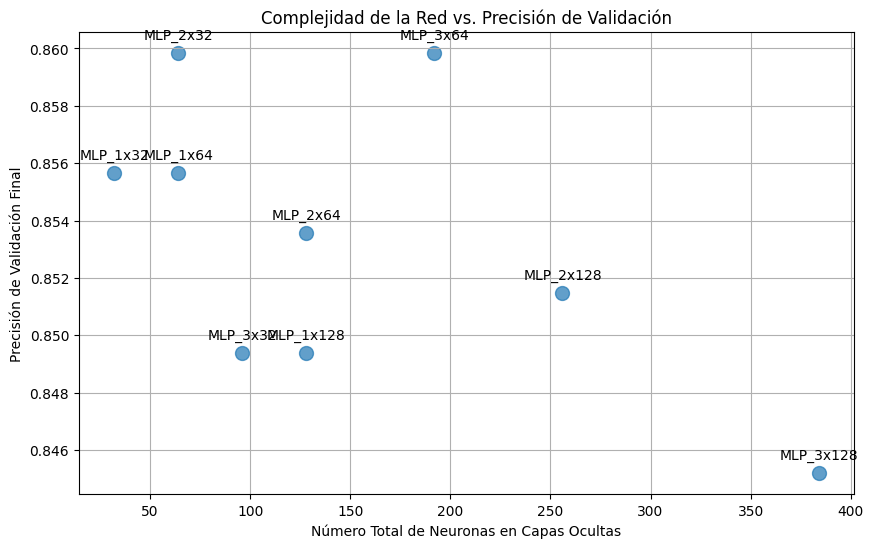

In [15]:
import matplotlib.pyplot as plt

complexity_data = []
accuracy_data = []

for name, data in results.items():
    # Calcular la complejidad como el número total de neuronas en las capas ocultas
    hidden_layers = architectures[name]
    total_neurons = sum(hidden_layers)

    # Obtener la precisión final de validación
    final_accuracy = data['history']['val_accuracy'][-1]

    complexity_data.append(total_neurons)
    accuracy_data.append(final_accuracy)

# Crear el gráfico
plt.figure(figsize=(10, 6))
plt.scatter(complexity_data, accuracy_data, s=100, alpha=0.7)

# Añadir etiquetas a los puntos para identificar las arquitecturas
for i, name in enumerate(results.keys()):
    plt.annotate(name, (complexity_data[i], accuracy_data[i]), textcoords="offset points", xytext=(0,10), ha='center')

plt.title('Complejidad de la Red vs. Precisión de Validación')
plt.xlabel('Número Total de Neuronas en Capas Ocultas')
plt.ylabel('Precisión de Validación Final')
plt.grid(True)
plt.show()


### Pipeline de optimizadores

In [16]:
LEARNING_RATE = 0.01
EPOCHS = 50
BATCH_SIZE = 32

# El split fijo entrenamiento / validación (X_train_exp, y_train_exp,
# X_val, y_val) ya está definido en la sección de preparación de datos.


# --------------------------------------------------
# Optimizer configurations
# --------------------------------------------------

optimizer_configs = {

    # Full-batch Gradient Descent
    "Gradient Descent": {
        "optimizer": "sgd",
        "batch_size": len(X_train_exp),
        "momentum": 0.0
    },

    # Mini-Batch Gradient Descent
    "Mini-Batch Gradient Descent": {
        "optimizer": "sgd",
        "batch_size": BATCH_SIZE,
        "momentum": 0.0
    },

    # SGD + Momentum
    "SGD with Momentum": {
        "optimizer": "sgd",
        "batch_size": BATCH_SIZE,
        "momentum": 0.9
    },

    # Adaptive optimizers
    "AdaGrad": {
        "optimizer": "adagrad",
        "batch_size": BATCH_SIZE
    },

    "RMSProp": {
        "optimizer": "rmsprop",
        "batch_size": BATCH_SIZE
    },

    "Adam": {
        "optimizer": "adam",
        "batch_size": BATCH_SIZE
    }
}

In [17]:
def create_optimizer(model, config):

    optimizer_type = config["optimizer"]

    if optimizer_type == "sgd":
        return torch.optim.SGD(
            model.parameters(),
            lr=LEARNING_RATE,
            momentum=config.get("momentum", 0.0)
        )

    if optimizer_type == "adagrad":
        return torch.optim.Adagrad(
            model.parameters(),
            lr=LEARNING_RATE
        )

    if optimizer_type == "rmsprop":
        return torch.optim.RMSprop(
            model.parameters(),
            lr=LEARNING_RATE
        )

    if optimizer_type == "adam":
        return torch.optim.Adam(
            model.parameters(),
            lr=LEARNING_RATE
        )

    raise ValueError(
        f"Unknown optimizer: {optimizer_type}"
    )

In [18]:
torch.manual_seed(123)

base_model = MLP(
    input_size=input_size,
    output_size=1,
    hidden_layers=[64, 64]
)

initial_weights = base_model.state_dict()

In [19]:
def train_mlp(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    optimizer,
    batch_size,
    epochs
):

    criterion = nn.BCEWithLogitsLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    dataset = TensorDataset(X_train, y_train)

    train_loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            correct += (
                predictions == y_batch
            ).sum().item()

            total += y_batch.size(0)

        train_loss = total_loss / len(train_loader)
        train_accuracy = correct / total

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_loss = criterion(
                val_outputs,
                y_val
            )

            val_predictions = (
                torch.sigmoid(val_outputs) >= 0.5
            ).float()

            val_accuracy = (
                (val_predictions == y_val)
                .sum()
                .item()
                / len(y_val)
            )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss.item())
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

    return history

In [20]:
results = {}


for optimizer_name, config in optimizer_configs.items():

    print(f"Training: {optimizer_name}")

    # Same architecture
    model = MLP(
        input_size=input_size,
        output_size=1,
        hidden_layers=[64, 64]
    )

    # Same initial weights
    model.load_state_dict(initial_weights)

    # Different optimizer
    optimizer = create_optimizer(
        model,
        config
    )

    history = train_mlp(
        model=model,
        X_train=X_train_exp,
        y_train=y_train_exp,
        X_val=X_val,
        y_val=y_val,
        optimizer=optimizer,
        batch_size=config["batch_size"],
        epochs=EPOCHS
    )

    results[optimizer_name] = {
        "model": model,
        "history": history
    }

    print(
        f"Final validation accuracy: "
        f"{history['val_accuracy'][-1]:.4f}"
    )

Training: Gradient Descent


Final validation accuracy: 0.7552
Training: Mini-Batch Gradient Descent


Final validation accuracy: 0.8556
Training: SGD with Momentum


Final validation accuracy: 0.8368
Training: AdaGrad


Final validation accuracy: 0.8389
Training: RMSProp


Final validation accuracy: 0.8431
Training: Adam


Final validation accuracy: 0.8473


In [21]:
criterion = nn.BCEWithLogitsLoss()

# X_test_tensor y y_test_tensor vienen de la sección de preparación de datos.

for optimizer_name, result in results.items():

    model = result["model"]

    model.eval()

    with torch.no_grad():
        test_outputs = model(X_test_tensor)

        test_loss = criterion(
            test_outputs,
            y_test_tensor
        ).item()

    results[optimizer_name]["test_loss"] = test_loss

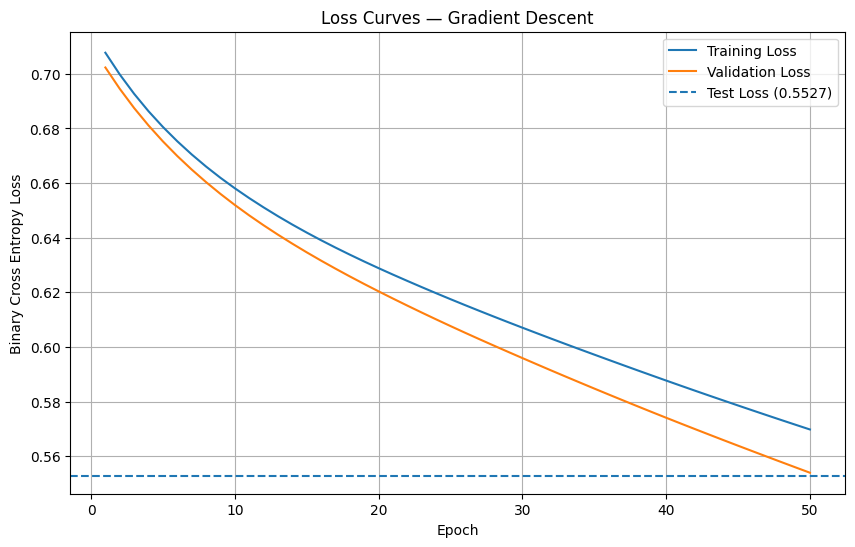

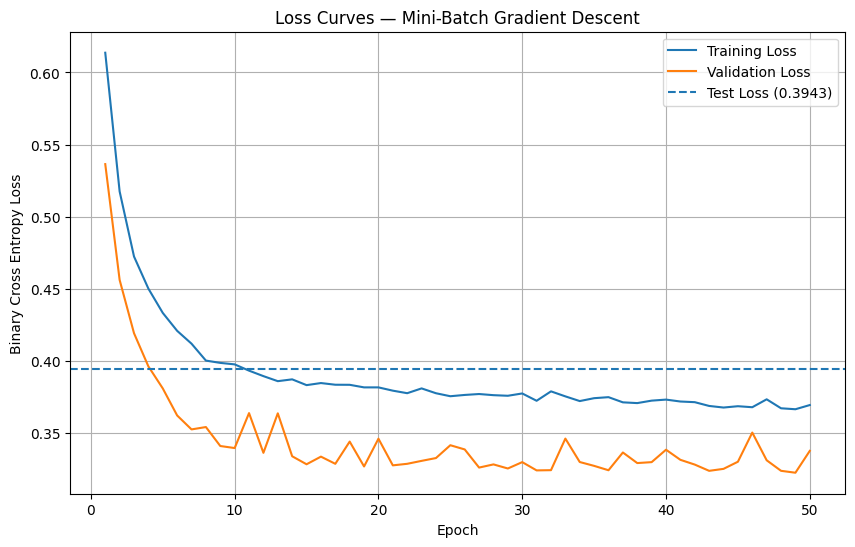

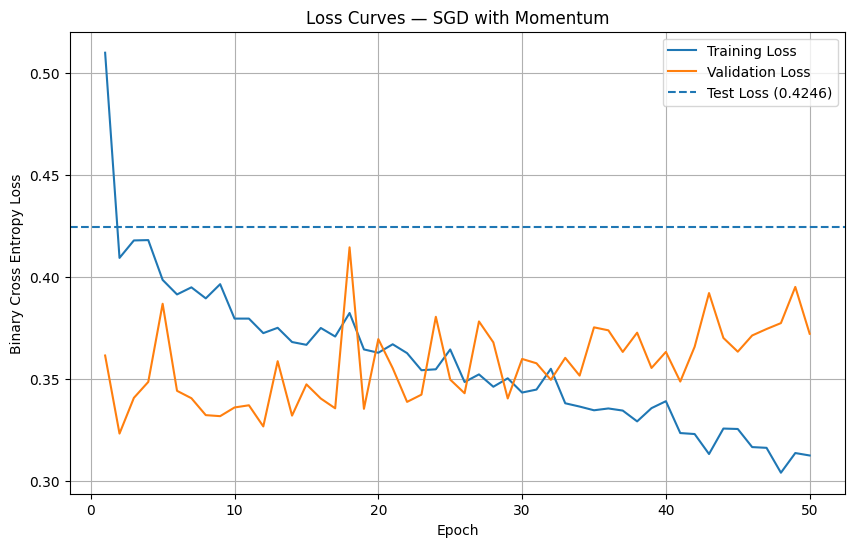

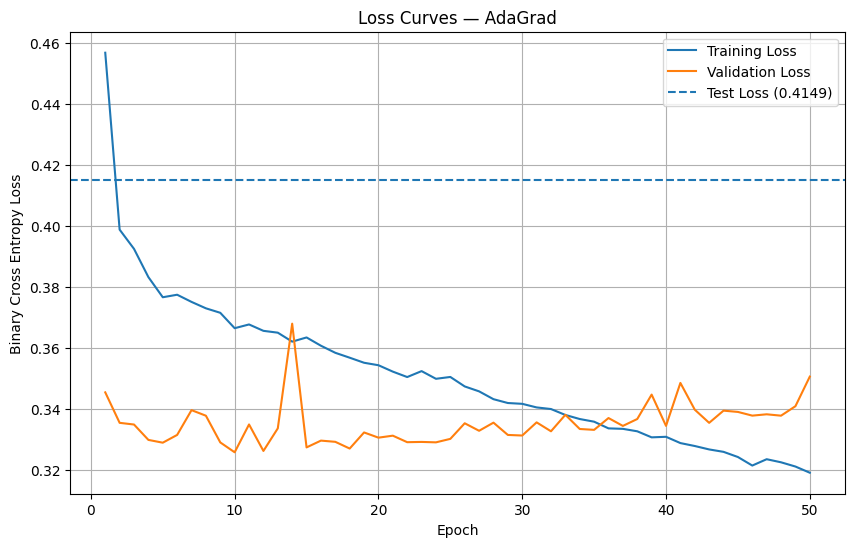

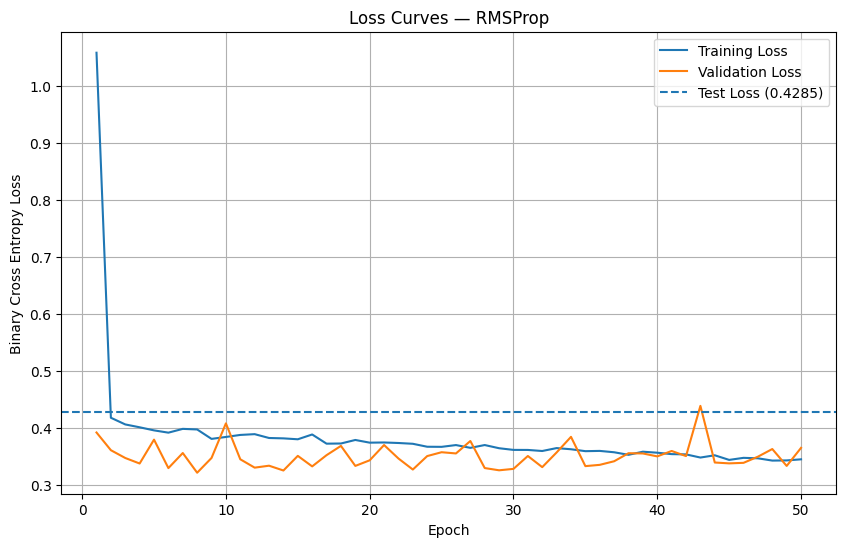

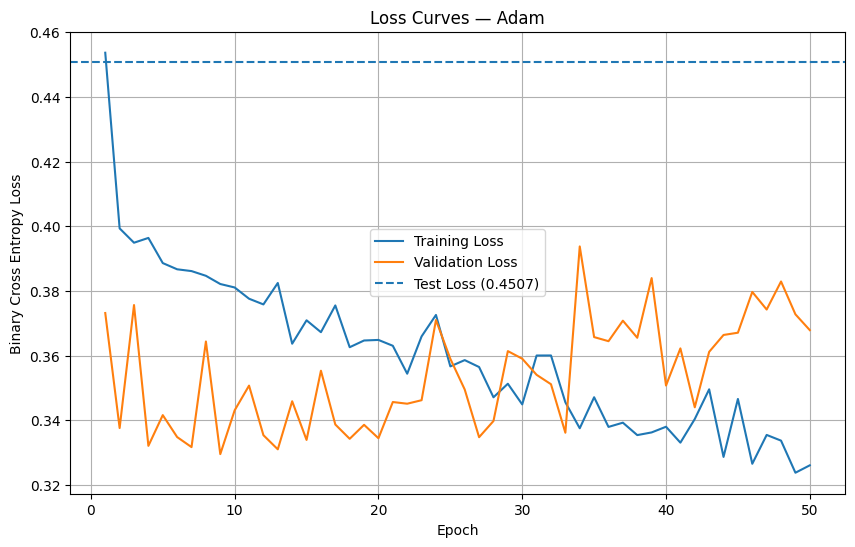

In [22]:
import matplotlib.pyplot as plt

for optimizer_name, result in results.items():

    history = result["history"]
    test_loss = result["test_loss"]

    epochs = range(1, EPOCHS + 1)

    plt.figure(figsize=(10, 6))

    # Training loss
    plt.plot(
        epochs,
        history["train_loss"],
        label="Training Loss"
    )

    # Validation loss
    plt.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss"
    )

    # Test loss
    plt.axhline(
        y=test_loss,
        linestyle="--",
        label=f"Test Loss ({test_loss:.4f})"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross Entropy Loss")
    plt.title(f"Loss Curves — {optimizer_name}")

    plt.legend()
    plt.grid(True)

    plt.show()

### Experimento: diferentes Learning Rates

In [23]:
# ============================================================
# EXPERIMENTO: IMPACTO DEL LEARNING RATE
# Se mantiene fija la arquitectura [64, 64] y se modifica
# únicamente la tasa de aprendizaje.
# ============================================================

learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]

learning_rate_results = {}


for lr in learning_rates:

    print(f"\nEntrenando con learning rate = {lr}")

    # Misma arquitectura utilizada en las pruebas de optimizadores
    model = MLP(
        input_size=input_size,
        output_size=1,
        hidden_layers=[64, 64]
    )

    # Misma inicialización para hacer comparable el experimento
    model.load_state_dict(initial_weights)

    # Optimizador SGD
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr
    )

    history = train_mlp(
        model=model,
        X_train=X_train_exp,
        y_train=y_train_exp,
        X_val=X_val,
        y_val=y_val,
        optimizer=optimizer,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS
    )

    learning_rate_results[lr] = {
        "model": model,
        "history": history
    }

    print(
        f"Accuracy final de validación: "
        f"{history['val_accuracy'][-1]:.4f}"
    )


Entrenando con learning rate = 0.001


Accuracy final de validación: 0.8410

Entrenando con learning rate = 0.005


Accuracy final de validación: 0.8598

Entrenando con learning rate = 0.01


Accuracy final de validación: 0.8494

Entrenando con learning rate = 0.05


Accuracy final de validación: 0.8556

Entrenando con learning rate = 0.1


Accuracy final de validación: 0.8410


In [24]:
# ============================================================
# COMPARACIÓN DE LEARNING RATES
# ============================================================

learning_rate_summary = []

for lr, result in learning_rate_results.items():

    history = result["history"]

    learning_rate_summary.append({
        "learning_rate": lr,
        "val_accuracy_final": history["val_accuracy"][-1],
        "val_loss_final": history["val_loss"][-1],
        "train_accuracy_final": history["train_accuracy"][-1],
        "train_loss_final": history["train_loss"][-1]
    })

learning_rate_summary = pd.DataFrame(learning_rate_summary)

display(
    learning_rate_summary.sort_values(
        by="val_accuracy_final",
        ascending=False
    )
)

,learning_rate,val_accuracy_final,val_loss_final,train_accuracy_final,train_loss_final
1,0.005,0.859833,0.331860,0.829243,0.373688
3,0.050,0.855649,0.354451,0.842820,0.330862
2,0.010,0.849372,0.340357,0.827154,0.367920
0,0.001,0.841004,0.376320,0.804178,0.421890
4,0.100,0.841004,0.388901,0.863185,0.316625


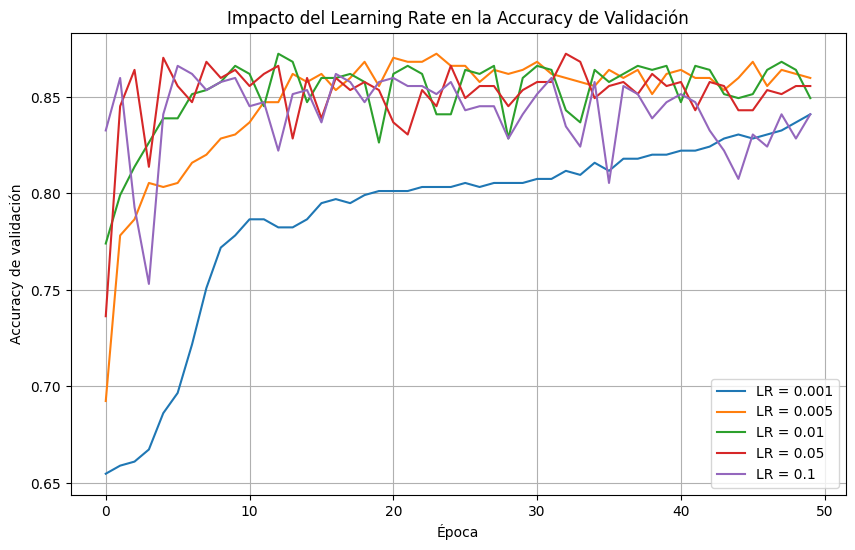

In [25]:
# ============================================================
# CURVAS DE VALIDACIÓN PARA LOS DIFERENTES LEARNING RATES
# ============================================================

plt.figure(figsize=(10, 6))

for lr, result in learning_rate_results.items():

    plt.plot(
        result["history"]["val_accuracy"],
        label=f"LR = {lr}"
    )

plt.xlabel("Época")
plt.ylabel("Accuracy de validación")
plt.title("Impacto del Learning Rate en la Accuracy de Validación")
plt.legend()
plt.grid(True)
plt.show()

### Experimento: función de pérdida

In [26]:
# ============================================================
# MODELO MLP PARA COMPARAR FUNCIONES DE PÉRDIDA
# La variante sigmoid permite utilizar BCELoss.
# ============================================================

class MLPBinarySigmoid(nn.Module):

    def __init__(self, input_size, hidden_layers):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_layers:
            layers.append(
                nn.Linear(previous_size, hidden_size)
            )
            layers.append(nn.ReLU())
            previous_size = hidden_size

        layers.append(
            nn.Linear(previous_size, 1)
        )

        layers.append(
            nn.Sigmoid()
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [27]:
# ============================================================
# ENTRENAMIENTO PARA COMPARAR FUNCIONES DE PÉRDIDA
# ============================================================

def train_mlp_loss_experiment(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    loss_function,
    optimizer,
    batch_size,
    epochs
):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    dataset = TensorDataset(X_train, y_train)

    train_loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = loss_function(
                outputs,
                y_batch
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            predictions = (
                outputs >= 0.5
            ).float()

            correct += (
                predictions == y_batch
            ).sum().item()

            total += y_batch.size(0)

        train_loss = total_loss / len(train_loader)
        train_accuracy = correct / total

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_loss = loss_function(
                val_outputs,
                y_val
            )

            val_predictions = (
                val_outputs >= 0.5
            ).float()

            val_accuracy = (
                (val_predictions == y_val)
                .sum()
                .item()
                / len(y_val)
            )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss.item())
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

    return history

In [28]:
# ============================================================
# EXPERIMENTO: COMPARACIÓN DE FUNCIONES DE PÉRDIDA
# Arquitectura fija: [64, 64]
# Optimizador fijo: SGD
# Learning rate fijo: 0.01
# ============================================================

loss_results = {}



# ------------------------------------------------------------
# 1. BCEWithLogitsLoss
# ------------------------------------------------------------

model_bce_logits = MLP(
    input_size=input_size,
    output_size=1,
    hidden_layers=[64, 64]
)

model_bce_logits.load_state_dict(initial_weights)

optimizer_bce_logits = torch.optim.SGD(
    model_bce_logits.parameters(),
    lr=0.01
)

history_bce_logits = train_mlp(
    model=model_bce_logits,
    X_train=X_train_exp,
    y_train=y_train_exp,
    X_val=X_val,
    y_val=y_val,
    optimizer=optimizer_bce_logits,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS
)

loss_results["BCEWithLogitsLoss"] = {
    "model": model_bce_logits,
    "history": history_bce_logits
}


# ------------------------------------------------------------
# 2. BCELoss
# ------------------------------------------------------------

model_bce = MLPBinarySigmoid(
    input_size=input_size,
    hidden_layers=[64, 64]
)

optimizer_bce = torch.optim.SGD(
    model_bce.parameters(),
    lr=0.01
)

history_bce = train_mlp_loss_experiment(
    model=model_bce,
    X_train=X_train_exp,
    y_train=y_train_exp,
    X_val=X_val,
    y_val=y_val,
    loss_function=nn.BCELoss(),
    optimizer=optimizer_bce,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS
)

loss_results["BCELoss"] = {
    "model": model_bce,
    "history": history_bce
}

In [29]:
# ============================================================
# RESUMEN DE FUNCIONES DE PÉRDIDA
# ============================================================

loss_summary = []

for loss_name, result in loss_results.items():

    history = result["history"]

    loss_summary.append({
        "loss_function": loss_name,
        "val_accuracy_final": history["val_accuracy"][-1],
        "val_loss_final": history["val_loss"][-1],
        "train_accuracy_final": history["train_accuracy"][-1],
        "train_loss_final": history["train_loss"][-1]
    })

loss_summary = pd.DataFrame(loss_summary)

display(
    loss_summary.sort_values(
        by="val_accuracy_final",
        ascending=False
    )
)

,loss_function,val_accuracy_final,val_loss_final,train_accuracy_final,train_loss_final
0,BCEWithLogitsLoss,0.864017,0.328823,0.833943,0.367830
1,BCELoss,0.855649,0.330939,0.836031,0.368263


### Experimento con regularización de parametros

Entrenando modelo con regularización L1 (lambda=0.0001)


  Accuracy final de validación (L1): 0.8598

Entrenando modelo con regularización L2 (weight_decay=0.0001)


  Accuracy final de validación (L2): 0.8619

--- Resumen de Resultados de Regularización ---


,regularization_type,val_accuracy_final,val_loss_final,train_accuracy_final,train_loss_final
1,L2_Regularization,0.861925,0.328608,0.827676,0.371699
0,L1_Regularization,0.859833,0.329851,0.837076,0.369938



--- Curvas de Aprendizaje con Regularización ---


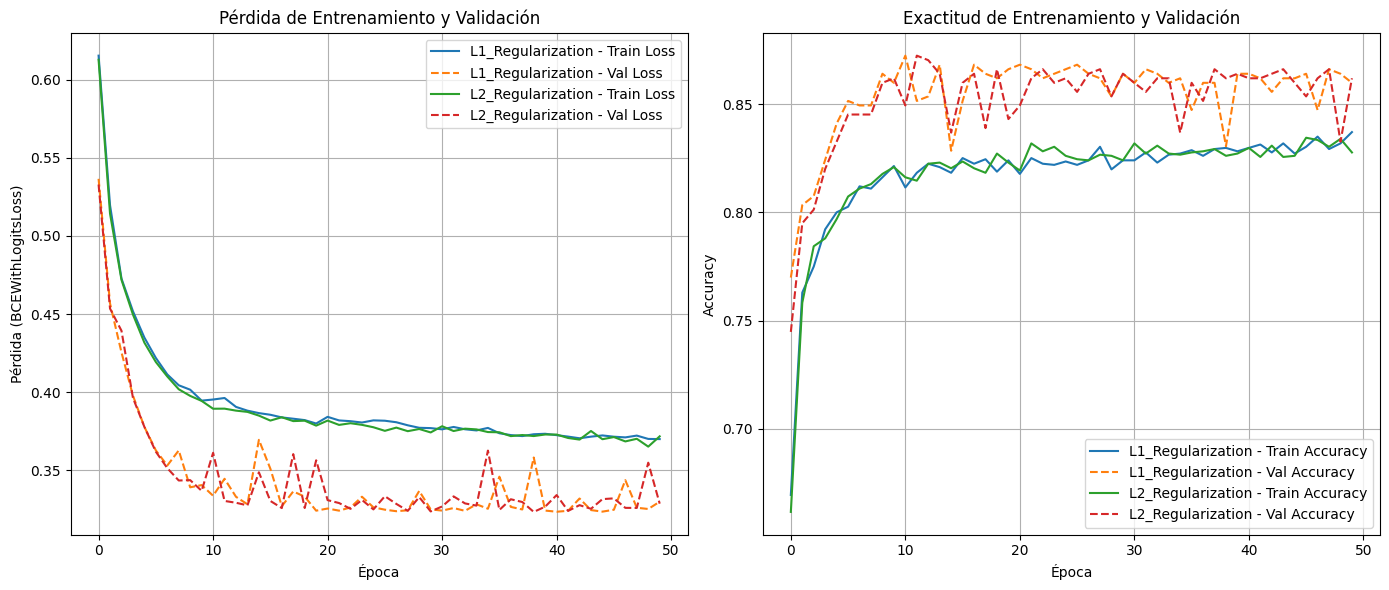

In [30]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import pandas as pd # Import pandas for the summary dataframe

# Reusing definitions from previous cells:
# MLP class is defined in Jc1SeGKgaWbh.
# input_size, initial_weights, X_train_exp, y_train_exp, X_val, y_val, BATCH_SIZE, EPOCHS, LEARNING_RATE are available from kernel state.

def train_mlp_regularization_experiment(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    optimizer,
    batch_size,
    epochs,
    l1_lambda=0.0
):
    criterion = nn.BCEWithLogitsLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    dataset = TensorDataset(X_train, y_train)

    train_loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            # Add L1 regularization if l1_lambda > 0
            if l1_lambda > 0:
                l1_norm = sum(torch.linalg.norm(p, 1) for p in model.parameters())
                loss = loss + l1_lambda * l1_norm

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            predictions = (torch.sigmoid(outputs) >= 0.5).float()
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

        train_loss = total_loss / len(train_loader)
        train_accuracy = correct / total

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val)

            val_predictions = (torch.sigmoid(val_outputs) >= 0.5).float()
            val_accuracy = ((val_predictions == y_val).sum().item() / len(y_val))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss.item())
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

    return history

# Define regularization parameters
L1_LAMBDA = 0.0001
L2_WEIGHT_DECAY = 0.0001 # This is equivalent to L2 regularization

regularization_results = {}

# --- Train with L1 regularization ---
print(f"Entrenando modelo con regularización L1 (lambda={L1_LAMBDA})")
model_l1 = MLP(
    input_size=input_size,
    output_size=1, # For binary classification with BCEWithLogitsLoss
    hidden_layers=[64, 64]
)
model_l1.load_state_dict(initial_weights) # Ensure consistent initialization
optimizer_l1 = torch.optim.SGD(
    model_l1.parameters(),
    lr=LEARNING_RATE
)
history_l1 = train_mlp_regularization_experiment(
    model=model_l1,
    X_train=X_train_exp,
    y_train=y_train_exp,
    X_val=X_val,
    y_val=y_val,
    optimizer=optimizer_l1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    l1_lambda=L1_LAMBDA
)
regularization_results["L1_Regularization"] = {
    "model": model_l1,
    "history": history_l1
}
print(f"  Accuracy final de validación (L1): {history_l1['val_accuracy'][-1]:.4f}")


# --- Train with L2 regularization (weight decay) ---
print(f"\nEntrenando modelo con regularización L2 (weight_decay={L2_WEIGHT_DECAY})")
model_l2 = MLP(
    input_size=input_size,
    output_size=1, # For binary classification with BCEWithLogitsLoss
    hidden_layers=[64, 64]
)
model_l2.load_state_dict(initial_weights) # Ensure consistent initialization
optimizer_l2 = torch.optim.SGD(
    model_l2.parameters(),
    lr=LEARNING_RATE,
    weight_decay=L2_WEIGHT_DECAY # L2 regularization via weight_decay
)

history_l2 = train_mlp_regularization_experiment(
    model=model_l2,
    X_train=X_train_exp,
    y_train=y_train_exp,
    X_val=X_val,
    y_val=y_val,
    optimizer=optimizer_l2,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    l1_lambda=0.0 # No L1 regularization for L2 model
)
regularization_results["L2_Regularization"] = {
    "model": model_l2,
    "history": history_l2
}
print(f"  Accuracy final de validación (L2): {history_l2['val_accuracy'][-1]:.4f}")

# --- Display Statistics ---
print("\n--- Resumen de Resultados de Regularización ---")
regularization_summary = []
for reg_type, result in regularization_results.items():
    history = result["history"]
    regularization_summary.append({
        "regularization_type": reg_type,
        "val_accuracy_final": history["val_accuracy"][-1],
        "val_loss_final": history["val_loss"][-1],
        "train_accuracy_final": history["train_accuracy"][-1],
        "train_loss_final": history["train_loss"][-1]
    })
regularization_summary_df = pd.DataFrame(regularization_summary)
display(regularization_summary_df.sort_values(by="val_accuracy_final", ascending=False))

# --- Plot Learning Curves ---
print("\n--- Curvas de Aprendizaje con Regularización ---")
plt.figure(figsize=(14, 6))

# Subplot for Loss
plt.subplot(1, 2, 1)
for reg_type, result in regularization_results.items():
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{reg_type} - Train Loss")
    plt.plot(history["val_loss"], label=f"{reg_type} - Val Loss", linestyle='--')
plt.title("Pérdida de Entrenamiento y Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (BCEWithLogitsLoss)")
plt.legend()
plt.grid(True)

# Subplot for Accuracy
plt.subplot(1, 2, 2)
for reg_type, result in regularization_results.items():
    history = result["history"]
    plt.plot(history["train_accuracy"], label=f"{reg_type} - Train Accuracy")
    plt.plot(history["val_accuracy"], label=f"{reg_type} - Val Accuracy", linestyle='--')
plt.title("Exactitud de Entrenamiento y Validación")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Pipeline de pruebas final

En esta sección se prueban **todas las combinaciones** de los hiperparámetros explorados individualmente en las secciones anteriores:

| Factor | Valores |
|---|---|
| Arquitectura (capas ocultas) | `[32]`, `[128, 128]`, `[128, 128, 128]` |
| Optimizador | AdaGrad, Mini-Batch GD, GD (batch completo) |
| Learning rate | 0.005, 0.01, 0.05 |
| Función de pérdida | BCE (`BCEWithLogitsLoss`) |
| Regularización | L1, L2 |
| Épocas | 75 |

En total son 4 × 3 × 3 × 2 = **108 entrenamientos**. Para que la comparación sea justa:

- Todas las corridas usan el mismo split fijo de entrenamiento/validación definido en la sección de preparación de datos.
- Todas las corridas con la misma arquitectura parten de los **mismos pesos iniciales**.
- La penalización L1 o L2 se suma a la pérdida solo para calcular los gradientes; las pérdidas que se reportan y grafican son la BCE pura, así que son comparables entre L1 y L2 y entre entrenamiento y validación.
- La mejor configuración se escoge por su desempeño en **validación**; el conjunto de prueba solo se usa para reportar el resultado final.


In [31]:
# ============================================================
# PIPELINE FINAL: CONFIGURACIÓN Y FUNCIÓN DE ENTRENAMIENTO
# Usa: MLP (clase definida antes), input_size, X_train_exp, y_train_exp,
#      X_val, y_val, X_test_tensor, y_test_tensor, y_test
# ============================================================
import copy
import itertools
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# ------------------------------------------------------------
# 1. Espacio de búsqueda
# ------------------------------------------------------------
FINAL_EPOCHS = 75
FINAL_BATCH_SIZE = 32
SEED = 42

final_architectures = {
    "[32]": [32],
    "[128, 128]": [128, 128],
    "[64, 64]": [64, 64],
    "[128, 128, 128]": [128, 128, 128],
}

final_optimizers = ["AdaGrad", "Mini-Batch GD", "GD"]
final_learning_rates = [0.005, 0.01, 0.05]
final_loss = "BCE"
final_regularizations = ["L1", "L2", "Ninguna"]

# Intensidad de la regularización (misma escala usada en el experimento anterior)
REG_LAMBDA = {
    "L1": 1e-4,
    "L2": 1e-4,
}

combinaciones = list(itertools.product(
    final_architectures.keys(),
    final_optimizers,
    final_learning_rates,
    final_regularizations
))
print(f"Total de combinaciones a entrenar: {len(combinaciones)}")

# ------------------------------------------------------------
# 2. Pesos iniciales: uno por arquitectura (compartido por todas sus corridas)
# ------------------------------------------------------------
pesos_iniciales_final = {}
for arch_name, hidden in final_architectures.items():
    torch.manual_seed(SEED)
    modelo_base = MLP(input_size=input_size, output_size=1, hidden_layers=hidden)
    pesos_iniciales_final[arch_name] = copy.deepcopy(modelo_base.state_dict())


# ------------------------------------------------------------
# 3. Funciones auxiliares
# ------------------------------------------------------------
def crear_optimizador(nombre, parametros, lr):
    """AdaGrad, Mini-Batch GD y GD (el GD usa batch completo, ver batch_size_para)."""
    if nombre == "AdaGrad":
        return torch.optim.Adagrad(parametros, lr=lr)
    if nombre in ("Mini-Batch GD", "GD"):
        return torch.optim.SGD(parametros, lr=lr, momentum=0.0)
    raise ValueError(f"Optimizador desconocido: {nombre}")


def batch_size_para(nombre_optimizador, n_muestras):
    # GD = descenso de gradiente con TODO el conjunto de entrenamiento por paso
    return n_muestras if nombre_optimizador == "GD" else FINAL_BATCH_SIZE


def penalizacion(model, tipo):
    """Penalización L1 o L2 sobre los pesos (no sobre los sesgos)."""
    pesos = [p for nombre, p in model.named_parameters() if "weight" in nombre]
    if tipo == "L1":
        return REG_LAMBDA["L1"] * sum(p.abs().sum() for p in pesos)
    if tipo == "L2":
        return REG_LAMBDA["L2"] * sum((p ** 2).sum() for p in pesos)
    return torch.tensor(0.0)


def evaluar(model, X, y, criterion):
    """Devuelve pérdida BCE, accuracy, probabilidades y predicciones."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        proba = torch.sigmoid(logits)
        pred = (proba >= 0.5).float()
        acc = (pred == y).float().mean().item()
    return loss, acc, proba.view(-1).numpy(), pred.view(-1).numpy().astype(int)


def entrenar_configuracion(arch_name, optimizador, lr, regularizacion):
    hidden = final_architectures[arch_name]

    model = MLP(input_size=input_size, output_size=1, hidden_layers=hidden)
    model.load_state_dict(pesos_iniciales_final[arch_name])

    optimizer = crear_optimizador(optimizador, model.parameters(), lr)
    criterion = nn.BCEWithLogitsLoss()   # BCE aplicada sobre logits (numéricamente estable)

    # Generador propio -> mismo orden de mini-batches en todas las corridas
    generador = torch.Generator().manual_seed(SEED)
    loader = DataLoader(
        TensorDataset(X_train_exp, y_train_exp),
        batch_size=batch_size_para(optimizador, len(X_train_exp)),
        shuffle=True,
        generator=generador
    )

    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
    inicio = time.time()

    for epoch in range(FINAL_EPOCHS):
        model.train()
        suma_loss, correctos, total = 0.0, 0, 0

        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            logits = model(X_batch)
            loss_bce = criterion(logits, y_batch)
            loss_total = loss_bce + penalizacion(model, regularizacion)
            loss_total.backward()
            optimizer.step()

            # Se registra la BCE pura (sin la penalización) para comparar curvas
            suma_loss += loss_bce.item() * y_batch.size(0)
            correctos += ((torch.sigmoid(logits) >= 0.5).float() == y_batch).sum().item()
            total += y_batch.size(0)

        val_loss, val_acc, _, _ = evaluar(model, X_val, y_val, criterion)

        history["train_loss"].append(suma_loss / total)
        history["train_accuracy"].append(correctos / total)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

    tiempo = time.time() - inicio

    mejor_epoca = int(np.argmax(history["val_accuracy"])) + 1

    fila = {
        "arquitectura": arch_name,
        "optimizador": optimizador,
        "learning_rate": lr,
        "perdida": final_loss,
        "regularizacion": regularizacion,
        "parametros": sum(p.numel() for p in model.parameters()),
        "train_loss": history["train_loss"][-1],
        "val_loss": history["val_loss"][-1],
        "min_val_loss": min(history["val_loss"]),
        "train_acc": history["train_accuracy"][-1],
        "val_acc": history["val_accuracy"][-1],
        "mejor_val_acc": max(history["val_accuracy"]),
        "mejor_epoca": mejor_epoca,
        "brecha_loss": history["val_loss"][-1] - history["train_loss"][-1],
        "brecha_acc": history["train_accuracy"][-1] - history["val_accuracy"][-1],
        "tiempo_s": tiempo,
    }
    return model, history, fila


Total de combinaciones a entrenar: 108


In [32]:
# ============================================================
# PIPELINE FINAL: ENTRENAMIENTO DE TODAS LAS COMBINACIONES
# ============================================================
final_results = {}
final_rows = []

inicio_total = time.time()

for n, (arch_name, optimizador, lr, reg) in enumerate(combinaciones, start=1):

    clave = (arch_name, optimizador, lr, reg)
    model, history, fila = entrenar_configuracion(arch_name, optimizador, lr, reg)

    final_results[clave] = {"model": model, "history": history}
    final_rows.append(fila)

    print(
        f"[{n:02d}/{len(combinaciones)}] {arch_name:<16} | {optimizador:<13} | "
        f"lr={lr:<5} | {reg} -> val_acc={fila['val_acc']:.4f} | "
        f"val_loss={fila['val_loss']:.4f}"
    )

final_df = pd.DataFrame(final_rows)
print(f"\nTiempo total: {(time.time() - inicio_total) / 60:.1f} min")


[01/108] [32]             | AdaGrad       | lr=0.005 | L1 -> val_acc=0.8619 | val_loss=0.3267


[02/108] [32]             | AdaGrad       | lr=0.005 | L2 -> val_acc=0.8577 | val_loss=0.3259


[03/108] [32]             | AdaGrad       | lr=0.005 | Ninguna -> val_acc=0.8598 | val_loss=0.3254


[04/108] [32]             | AdaGrad       | lr=0.01  | L1 -> val_acc=0.8598 | val_loss=0.3261


[05/108] [32]             | AdaGrad       | lr=0.01  | L2 -> val_acc=0.8598 | val_loss=0.3270


[06/108] [32]             | AdaGrad       | lr=0.01  | Ninguna -> val_acc=0.8577 | val_loss=0.3242


... (98 outputs left out)

[105/108] [128, 128, 128]  | GD            | lr=0.01  | Ninguna -> val_acc=0.7678 | val_loss=0.5321


[106/108] [128, 128, 128]  | GD            | lr=0.05  | L1 -> val_acc=0.8452 | val_loss=0.3706


[107/108] [128, 128, 128]  | GD            | lr=0.05  | L2 -> val_acc=0.8452 | val_loss=0.3700


[108/108] [128, 128, 128]  | GD            | lr=0.05  | Ninguna -> val_acc=0.8452 | val_loss=0.3699

Tiempo total: 11.3 min


#### Tablas comparativas

In [33]:
# ============================================================
# TABLAS COMPARATIVAS
# ============================================================
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

# Orden de ranking: primero accuracy de validación, luego menor pérdida de validación
final_df_ordenado = final_df.sort_values(
    by=["val_acc", "val_loss"], ascending=[False, True]
).reset_index(drop=True)
final_df_ordenado.index = final_df_ordenado.index + 1
final_df_ordenado.index.name = "ranking"

formato = {
    "learning_rate": "{:.3f}",
    "train_loss": "{:.4f}", "val_loss": "{:.4f}", "min_val_loss": "{:.4f}", "test_loss": "{:.4f}",
    "train_acc": "{:.4f}", "val_acc": "{:.4f}", "mejor_val_acc": "{:.4f}",
    "brecha_loss": "{:+.4f}", "brecha_acc": "{:+.4f}",
    "tiempo_s": "{:.1f}", "parametros": "{:,}",
}

# ------------------------------------------------------------
# Tabla 1: todas las combinaciones (ordenadas por validación)
# ------------------------------------------------------------
print("TABLA 1 · Resultados de las 108 combinaciones (ordenadas por val_acc y val_loss)")
display(
    final_df_ordenado.style
    .format(formato)
    .background_gradient(subset=["val_acc"], cmap="Greens")
    .background_gradient(subset=["val_loss"], cmap="Reds")
)

# ------------------------------------------------------------
# Tabla 2: Top 10 con las métricas más relevantes
# ------------------------------------------------------------
cols_top = [
    "arquitectura", "optimizador", "learning_rate", "regularizacion",
    "val_acc", "val_loss", "mejor_val_acc", "mejor_epoca", "brecha_acc"
]
print("\nTABLA 2 · Top 10 configuraciones")
display(final_df_ordenado[cols_top].head(10).style.format(formato))

# ------------------------------------------------------------
# Tabla 3: efecto promedio de cada factor
# ------------------------------------------------------------
metricas_factor = ["val_acc", "val_loss", "brecha_acc", "tiempo_s"]

for factor in ["arquitectura", "optimizador", "learning_rate", "regularizacion"]:
    resumen = (
        final_df.groupby(factor)[metricas_factor]
        .agg(["mean", "std"])
        .round(4)
    )
    print(f"\nTABLA 3 · Efecto promedio de: {factor}")
    display(resumen)

# ------------------------------------------------------------
# Tabla 4: val_acc por arquitectura x (optimizador, learning rate) para cada regularización
# ------------------------------------------------------------
for reg in final_regularizations:
    pivote = final_df[final_df["regularizacion"] == reg].pivot_table(
        index="arquitectura",
        columns=["optimizador", "learning_rate"],
        values="val_acc"
    ).reindex(list(final_architectures.keys()))
    print(f"\nTABLA 4 · Accuracy de validación final — Regularización {reg}")
    display(pivote.style.format("{:.4f}").background_gradient(cmap="Greens", axis=None))

# ------------------------------------------------------------
# Tabla 5: L1 vs L2 lado a lado para cada configuración
# ------------------------------------------------------------
l1_vs_l2 = final_df.pivot_table(
    index=["arquitectura", "optimizador", "learning_rate"],
    columns="regularizacion",
    values=["val_acc", "val_loss"]
)
l1_vs_l2[("dif_val_acc", "L2 - L1")] = l1_vs_l2[("val_acc", "L2")] - l1_vs_l2[("val_acc", "L1")]
l1_vs_l2[("dif_val_acc", "L1 - Ninguna")] = l1_vs_l2[("val_acc", "L1")] - l1_vs_l2[("val_acc", "Ninguna")]
l1_vs_l2[("dif_val_acc", "L2 - Ninguna")] = l1_vs_l2[("val_acc", "L2")] - l1_vs_l2[("val_acc", "Ninguna")]
print("\nTABLA 5 · Comparación directa L1 vs L2")
display(l1_vs_l2.round(4))


TABLA 1 · Resultados de las 108 combinaciones (ordenadas por val_acc y val_loss)


,arquitectura,optimizador,learning_rate,perdida,regularizacion,parametros,train_loss,val_loss,min_val_loss,train_acc,val_acc,mejor_val_acc,mejor_epoca,brecha_loss,brecha_acc,tiempo_s
ranking,,,,,,,,,,,,,,,,
1,"[128, 128]",Mini-Batch GD,0.010,BCE,Ninguna,"21,377",0.3532,0.3262,0.3245,0.8423,0.8745,0.8745,75,-0.0270,-0.0322,8.0
2,"[128, 128]",Mini-Batch GD,0.010,BCE,L2,"21,377",0.3540,0.3263,0.3247,0.8418,0.8745,0.8745,74,-0.0278,-0.0327,8.3
3,"[128, 128]",Mini-Batch GD,0.010,BCE,L1,"21,377",0.3555,0.3260,0.3245,0.8413,0.8724,0.8724,51,-0.0295,-0.0311,7.9
4,[32],Mini-Batch GD,0.005,BCE,L1,"1,217",0.3720,0.3283,0.3274,0.8266,0.8724,0.8766,51,-0.0438,-0.0458,5.0
5,[32],Mini-Batch GD,0.005,BCE,L2,"1,217",0.3720,0.3283,0.3274,0.8272,0.8724,0.8745,51,-0.0437,-0.0452,5.3
6,[32],Mini-Batch GD,0.005,BCE,Ninguna,"1,217",0.3719,0.3284,0.3274,0.8272,0.8724,0.8745,51,-0.0435,-0.0452,5.1
7,"[128, 128, 128]",Mini-Batch GD,0.005,BCE,L1,"37,889",0.3673,0.3254,0.3254,0.8313,0.8703,0.8724,47,-0.0419,-0.0390,7.5
8,"[128, 128, 128]",Mini-Batch GD,0.005,BCE,L2,"37,889",0.3667,0.3255,0.3254,0.8319,0.8703,0.8724,67,-0.0412,-0.0384,7.9
9,"[128, 128]",Mini-Batch GD,0.005,BCE,Ninguna,"21,377",0.3659,0.3262,0.3255,0.8350,0.8703,0.8724,72,-0.0397,-0.0353,6.8



TABLA 2 · Top 10 configuraciones


,arquitectura,optimizador,learning_rate,regularizacion,val_acc,val_loss,mejor_val_acc,mejor_epoca,brecha_acc
ranking,,,,,,,,,
1,"[128, 128]",Mini-Batch GD,0.010,Ninguna,0.8745,0.3262,0.8745,75,-0.0322
2,"[128, 128]",Mini-Batch GD,0.010,L2,0.8745,0.3263,0.8745,74,-0.0327
3,"[128, 128]",Mini-Batch GD,0.010,L1,0.8724,0.3260,0.8724,51,-0.0311
4,[32],Mini-Batch GD,0.005,L1,0.8724,0.3283,0.8766,51,-0.0458
5,[32],Mini-Batch GD,0.005,L2,0.8724,0.3283,0.8745,51,-0.0452
6,[32],Mini-Batch GD,0.005,Ninguna,0.8724,0.3284,0.8745,51,-0.0452
7,"[128, 128, 128]",Mini-Batch GD,0.005,L1,0.8703,0.3254,0.8724,47,-0.0390
8,"[128, 128, 128]",Mini-Batch GD,0.005,L2,0.8703,0.3255,0.8724,67,-0.0384
9,"[128, 128]",Mini-Batch GD,0.005,Ninguna,0.8703,0.3262,0.8724,72,-0.0353



TABLA 3 · Efecto promedio de: arquitectura


val_acc         val_loss         brecha_acc         tiempo_s        
                   mean     std     mean     std       mean     std     mean     std
arquitectura                                                                        
[128, 128, 128]  0.8178  0.0567   0.4767  0.1932     0.0209  0.0762   6.3498  3.9821
[128, 128]       0.8363  0.0348   0.4053  0.0982     0.0098  0.0591   7.4208  3.6772
[32]             0.8474  0.0263   0.3635  0.0540    -0.0272  0.0194   4.1747  1.5249
[64, 64]         0.8290  0.0545   0.3982  0.0867    -0.0071  0.0357   7.2607  4.7446

... (7 outputs left out)


TABLA 4 · Accuracy de validación final — Regularización L2



TABLA 4 · Accuracy de validación final — Regularización Ninguna



TABLA 5 · Comparación directa L1 vs L2


val_acc                 val_loss                 dif_val_acc                          
regularizacion                                   L1      L2 Ninguna       L1      L2 Ninguna     L2 - L1 L1 - Ninguna L2 - Ninguna
arquitectura    optimizador   learning_rate                                                                                       
[128, 128, 128] AdaGrad       0.005          0.8515  0.8180  0.8347   0.3452  0.4682  0.4695     -0.0335       0.0167      -0.0167
                              0.010          0.8494  0.8096  0.8222   0.3768  0.8557  0.8956     -0.0397       0.0272      -0.0126
                              0.050          0.8494  0.8305  0.8033   0.3430  0.4731  1.0806     -0.0188       0.0460       0.0272
                GD            0.005          0.6841  0.6841  0.6841   0.5843  0.5842  0.5841      0.0000       0.0000       0.0000
                              0.010          0.7678  0.7678  0.7678   0.5324  0.5322  0.5321      0.0000       0.0000       0.0000
                              0.050          0.8452  0.8452  0.8452   0.3706  0.3700  0.3699      0.0000       0.0000       0.0000
                Mini-Batch GD 0.005          0.8703  0.8703  0.8682   0.3254  0.3255  0.3253      0.0000       0.0021       0.0021
                              0.010          0.8661  0.8661  0.8640   0.3263  0.3269  0.3268      0.0000       0.0021       0.0021
                              0.050          0.8473  0.8305  0.8368   0.3597  0.3884  0.3977     -0.0167       0.0105      -0.0063
[128, 128]      AdaGrad       0.005          0.8515  0.8515  0.8556   0.3342  0.3468  0.3461      0.0000      -0.0042      -0.0042
                              0.010          0.8556  0.8347  0.8326   0.3418  0.4310  0.4222     -0.0209       0.0230       0.0021
                              0.050          0.8410  0.8180  0.8013   0.3837  0.5299  0.7555     -0.0230       0.0397       0.0167
                GD            0.005          0.7741  0.7741  0.7741   0.5132  0.5131  0.5131      0.0000       0.0000       0.0000
                              0.010          0.7866  0.7866  0.7866   0.4637  0.4636  0.4635      0.0000       0.0000       0.0000
                              0.050          0.8577  0.8598  0.8577   0.3513  0.3510  0.3512      0.0021       0.0000       0.0021
                Mini-Batch GD 0.005          0.8703  0.8703  0.8703   0.3262  0.3262  0.3262      0.0000       0.0000       0.0000
                              0.010          0.8724  0.8745  0.8745   0.3260  0.3263  0.3262      0.0021      -0.0021       0.0000
                              0.050          0.8536  0.8452  0.8494   0.3594  0.3757  0.3761     -0.0084       0.0042      -0.0042
[32]            AdaGrad       0.005          0.8619  0.8577  0.8598   0.3267  0.3259  0.3254     -0.0042       0.0021      -0.0021
                              0.010          0.8598  0.8598  0.8577   0.3261  0.3270  0.3242      0.0000       0.0021       0.0021
                              0.050          0.8536  0.8431  0.8598   0.3392  0.3409  0.3455     -0.0105      -0.0063      -0.0167
                GD            0.005          0.7950  0.7950  0.7950   0.4772  0.4772  0.4772      0.0000       0.0000       0.0000
                              0.010          0.8075  0.8075  0.8075   0.4416  0.4415  0.4415      0.0000       0.0000       0.0000
                              0.050          0.8661  0.8661  0.8661   0.3498  0.3497  0.3497      0.0000       0.0000       0.0000
                Mini-Batch GD 0.005          0.8724  0.8724  0.8724   0.3283  0.3283  0.3284      0.0000       0.0000       0.0000
                              0.010          0.8661  0.8640  0.8640   0.3271  0.3262  0.3263     -0.0021       0.0021       0.0000
                              0.050          0.8515  0.8515  0.8452   0.3485  0.3550  0.3593      0.0000       0.0063       0.0063
[64, 64]        AdaGrad       0.005          0.8598  0.8640  0.8619   0.3289  0.3320  0.3329      0.0042      -0.0

#### Curvas de pérdida y accuracy por época

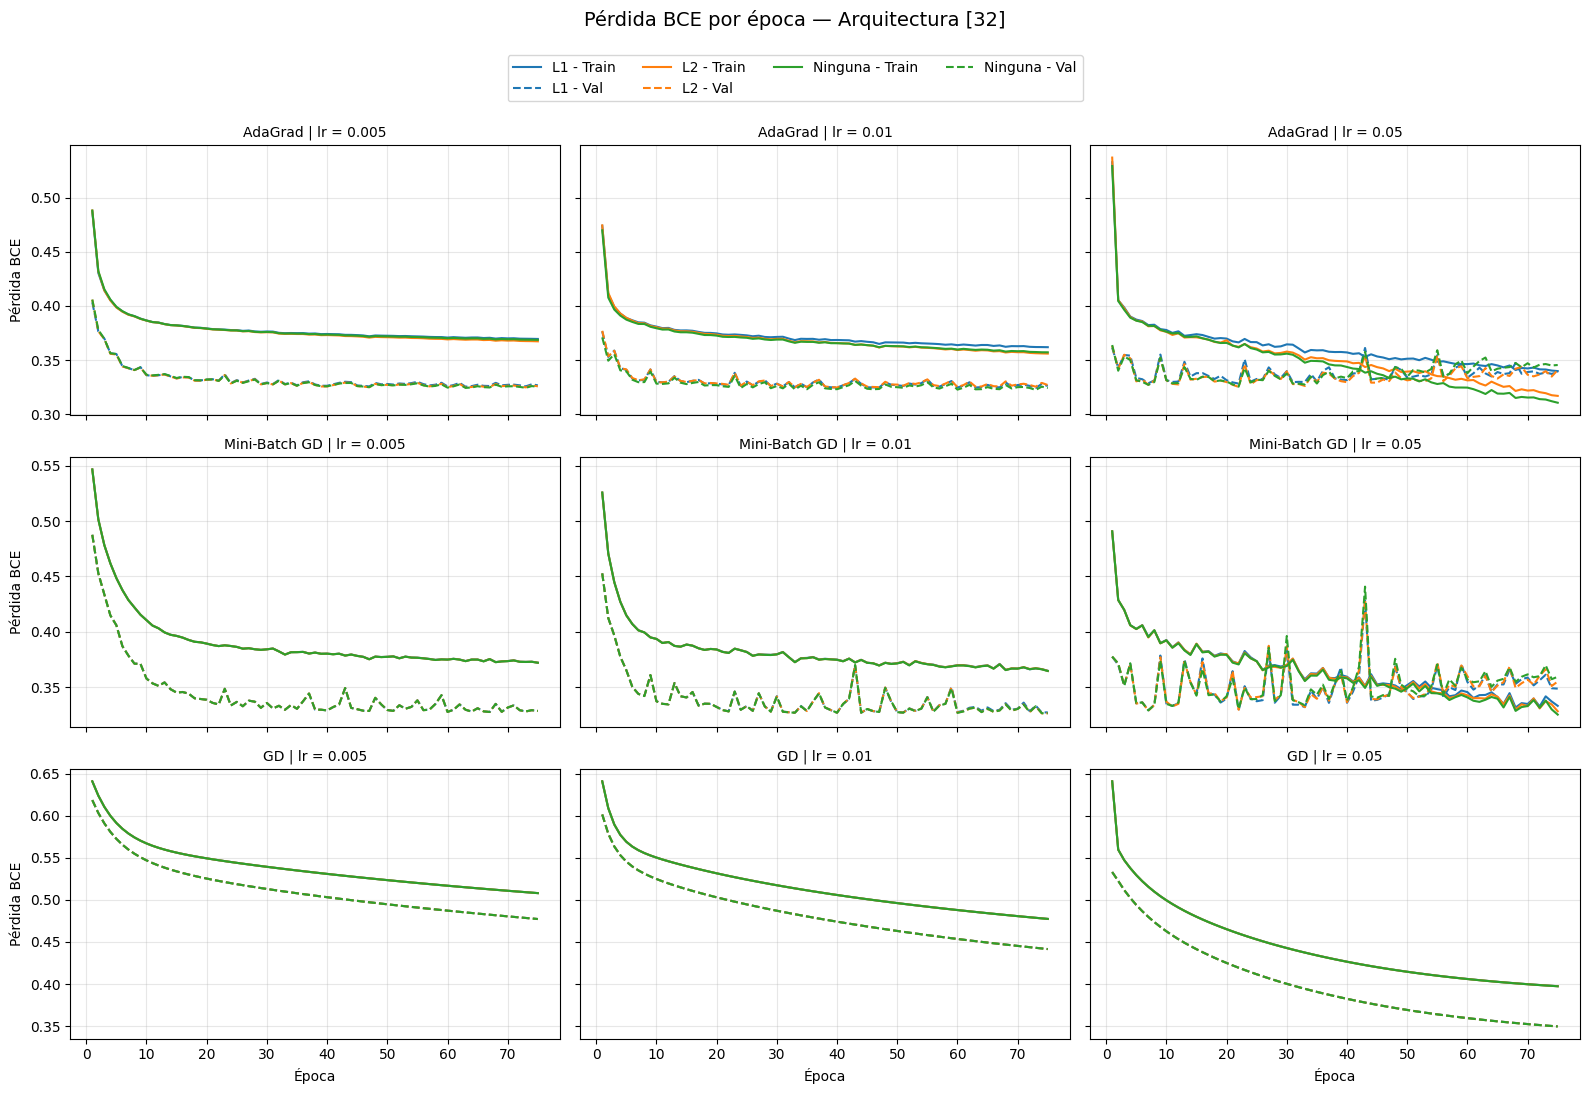

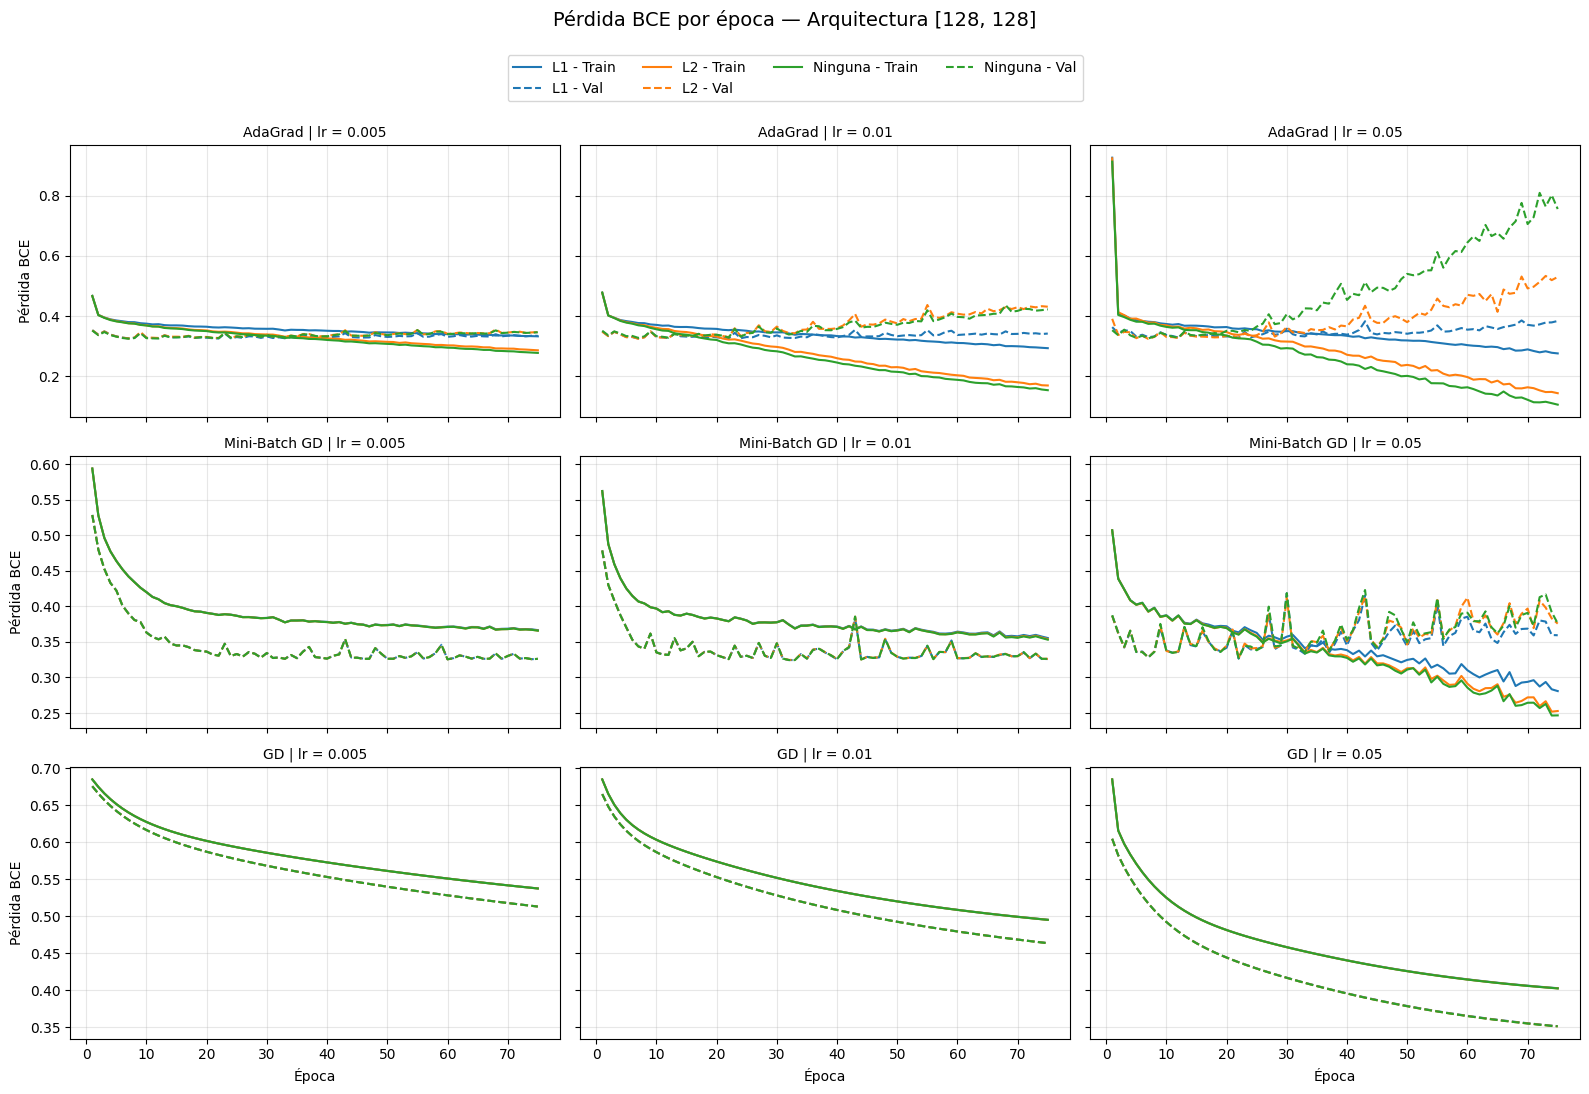

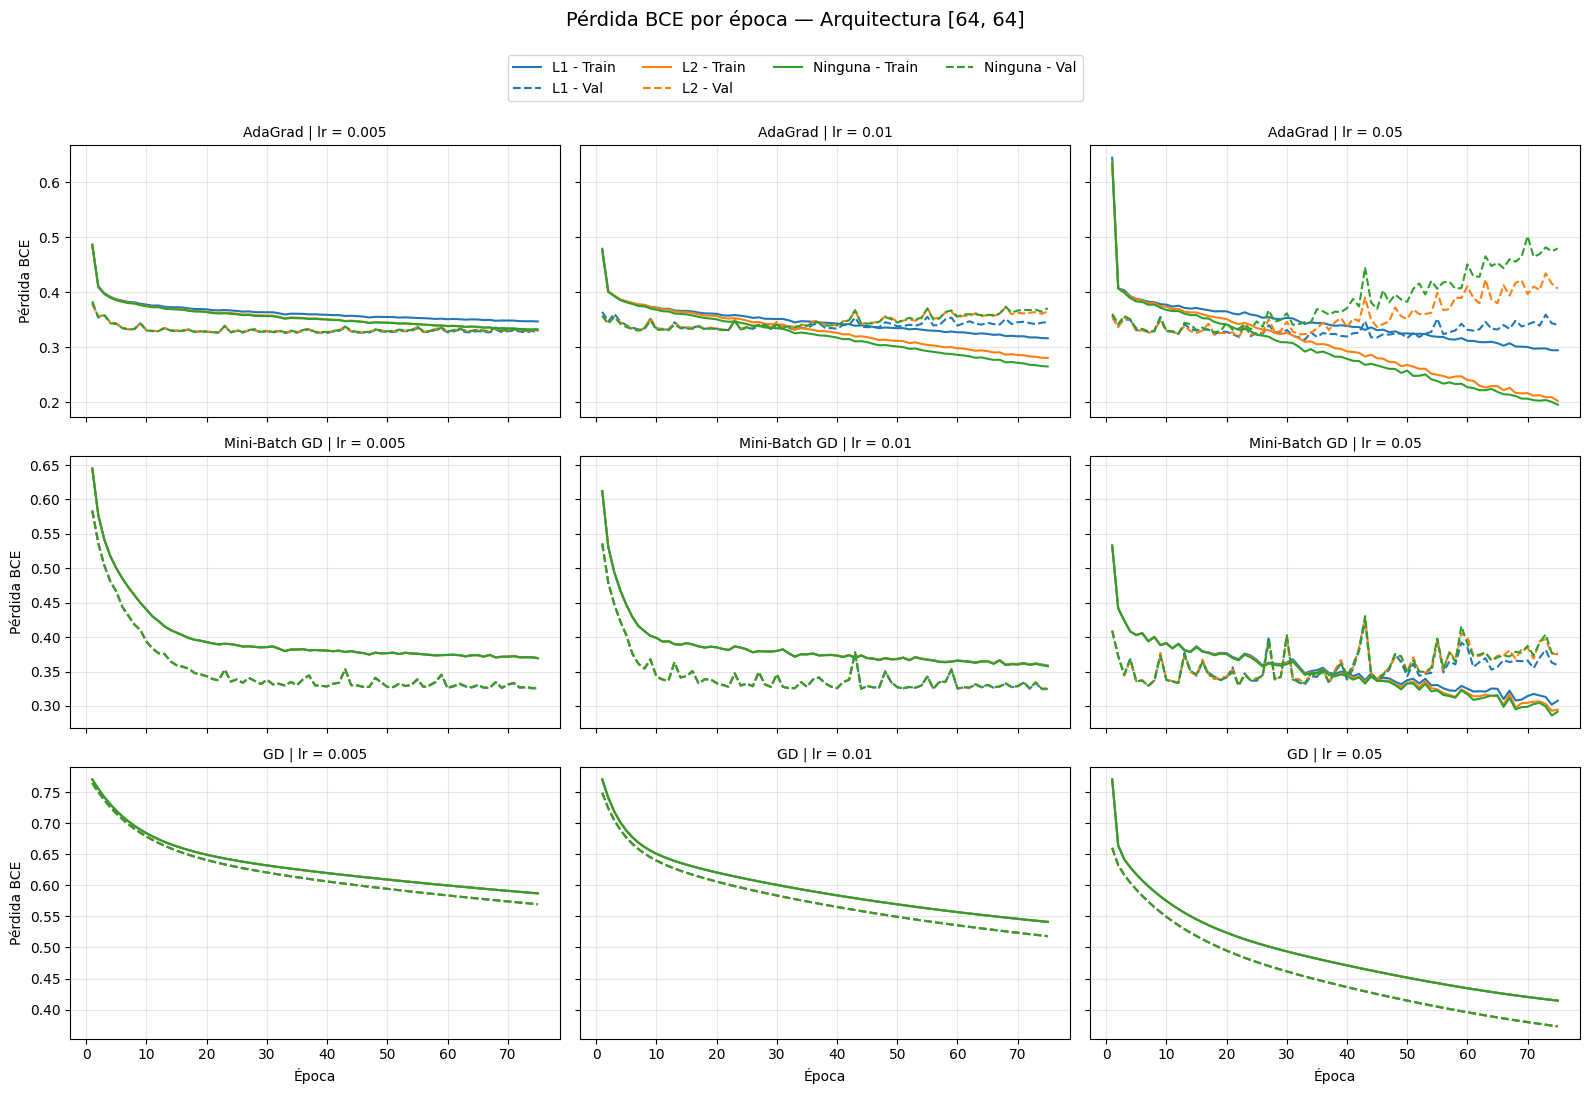

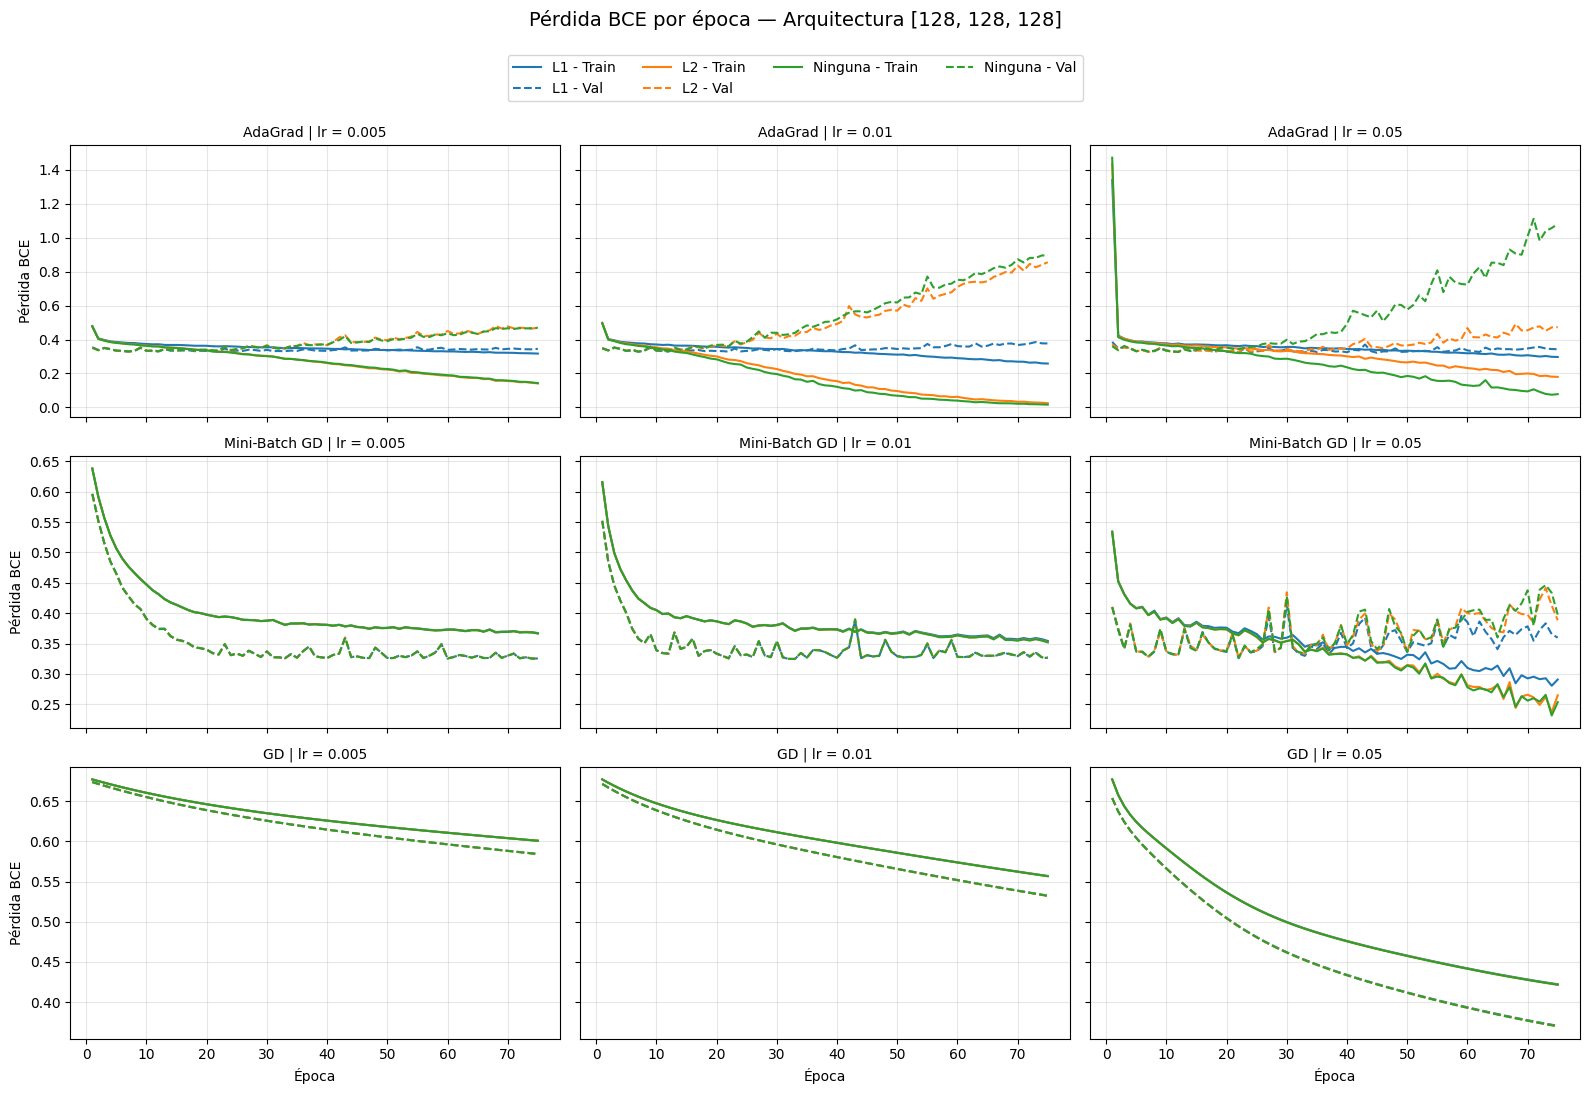

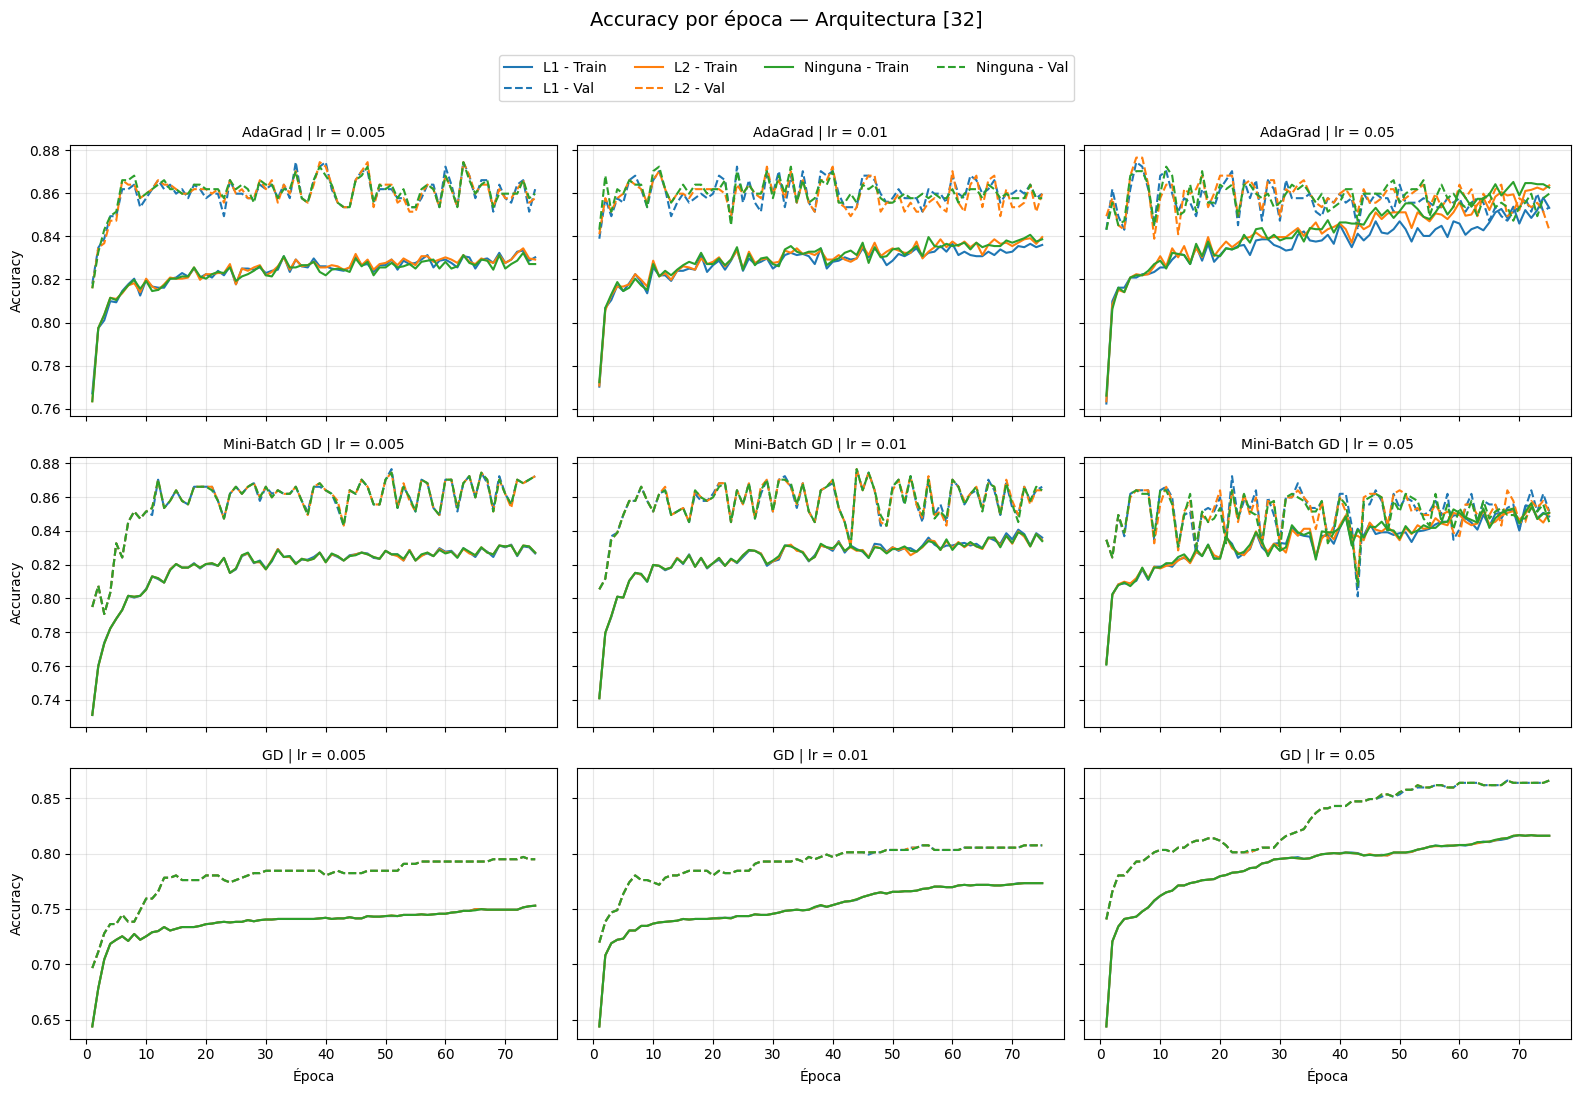

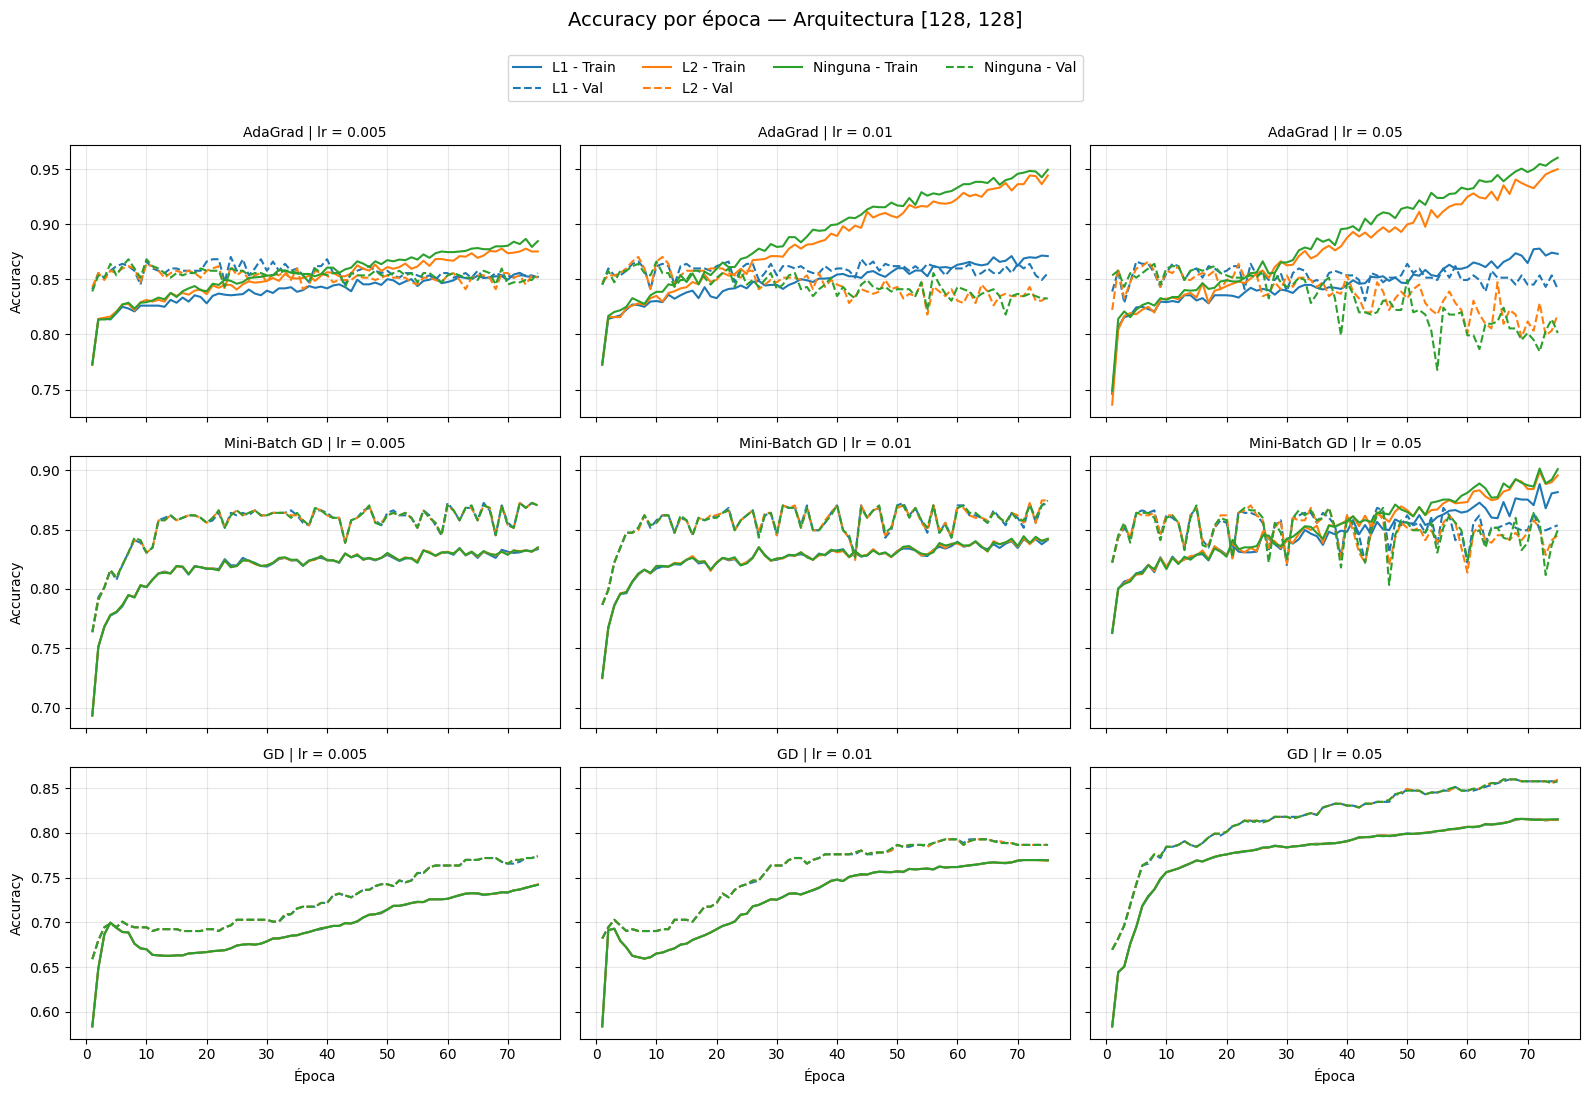

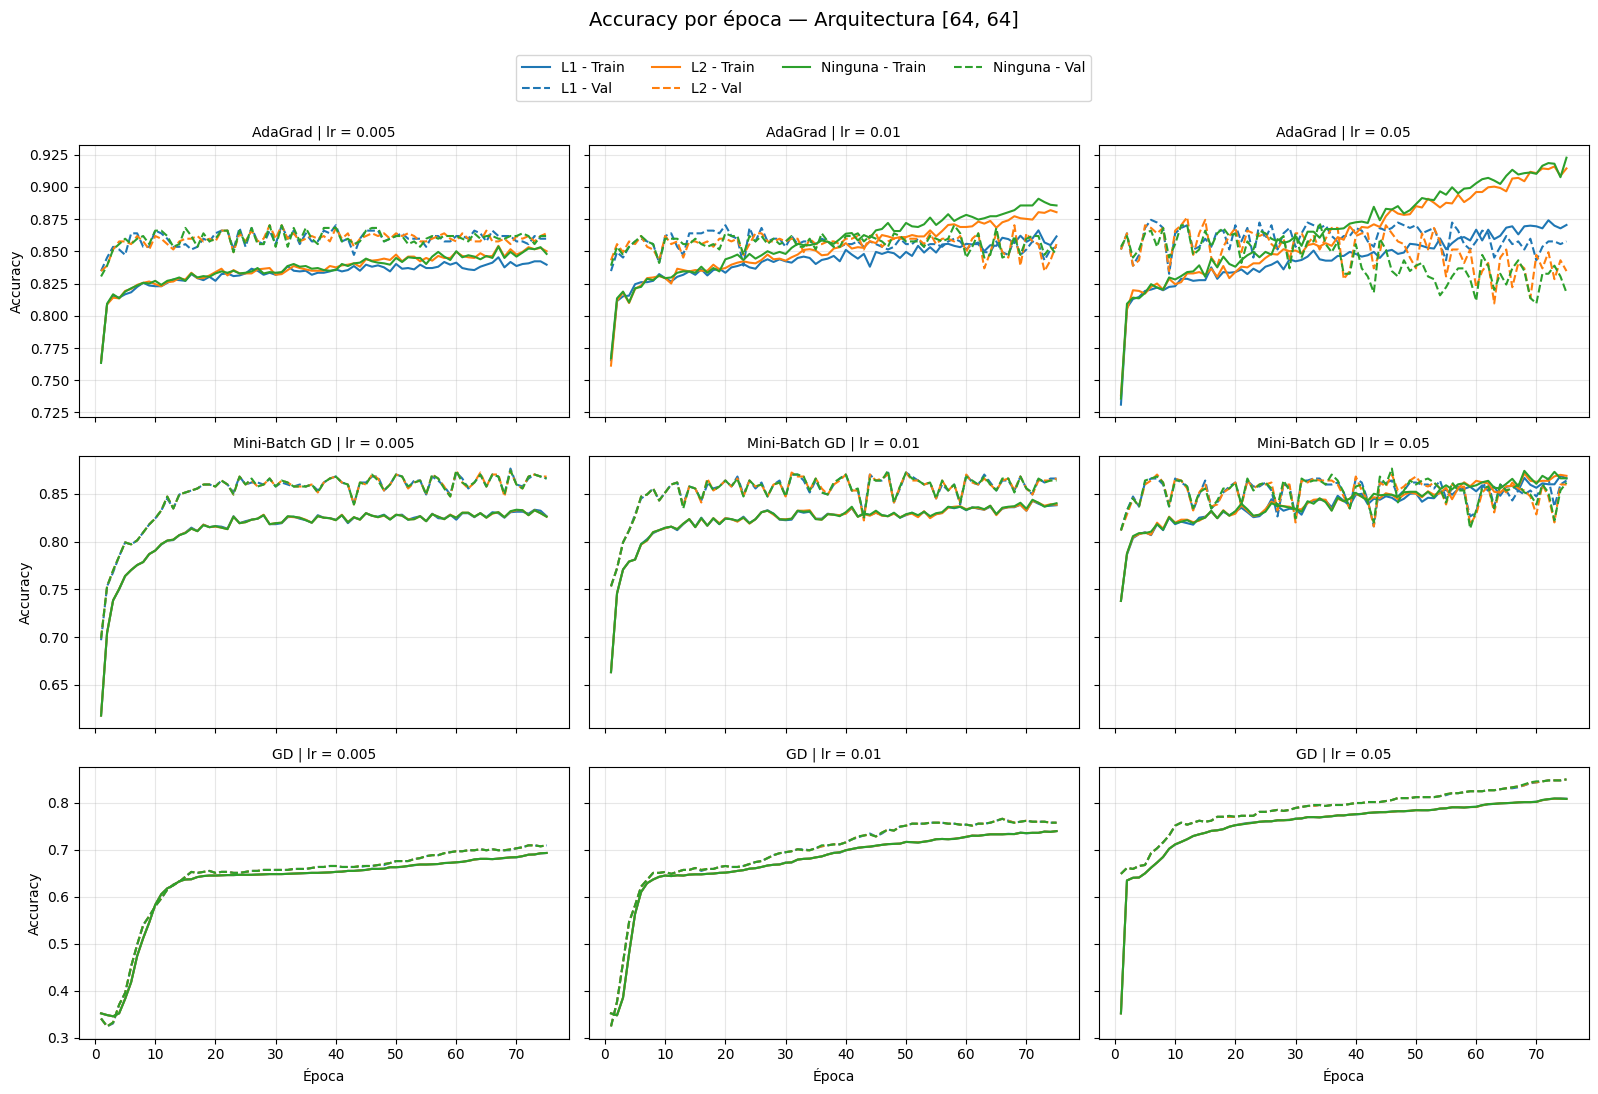

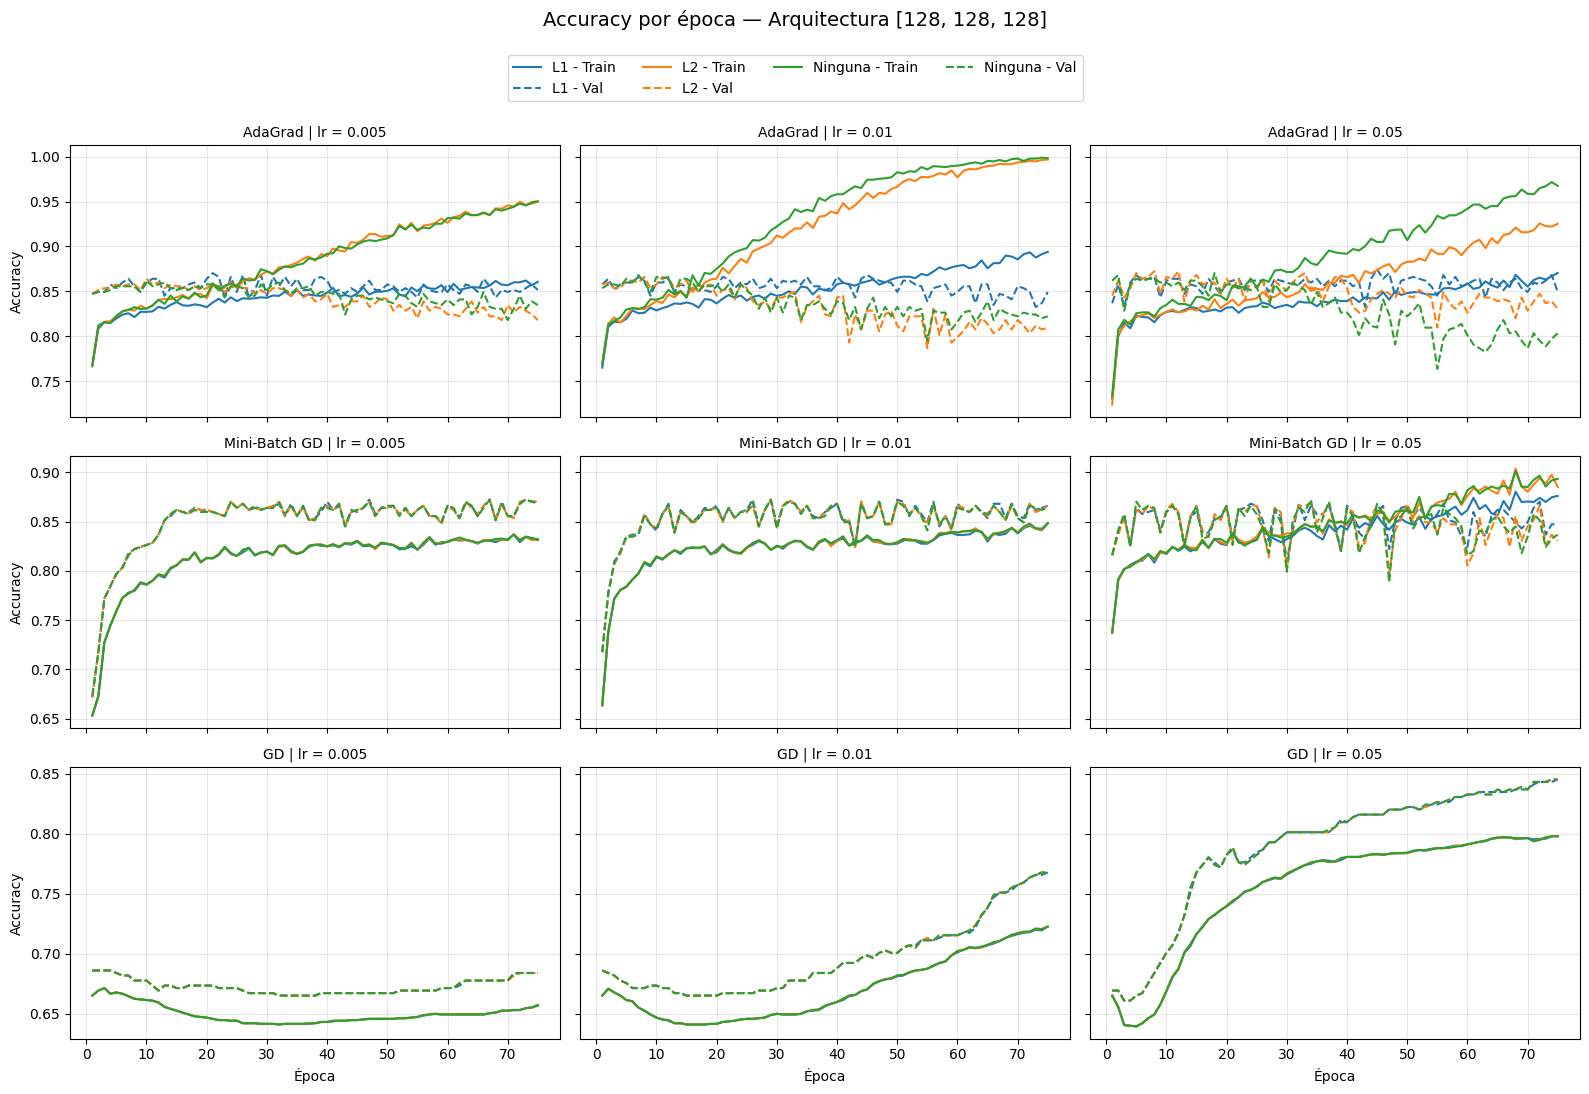

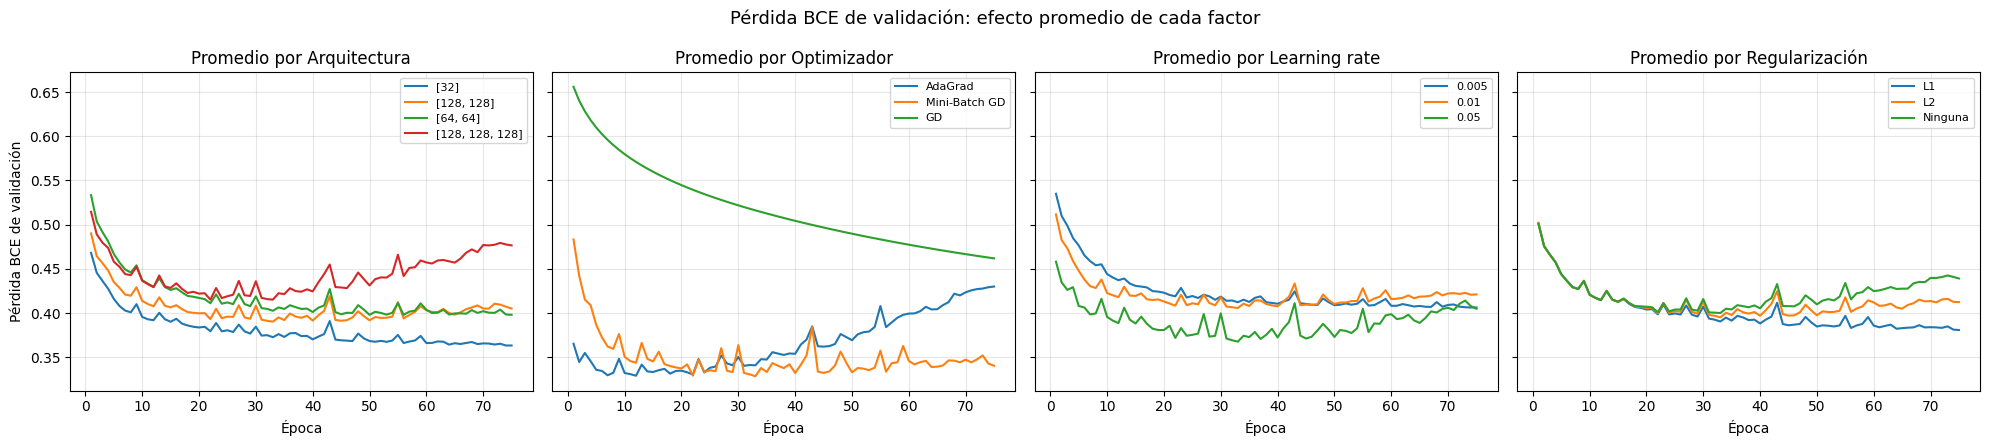

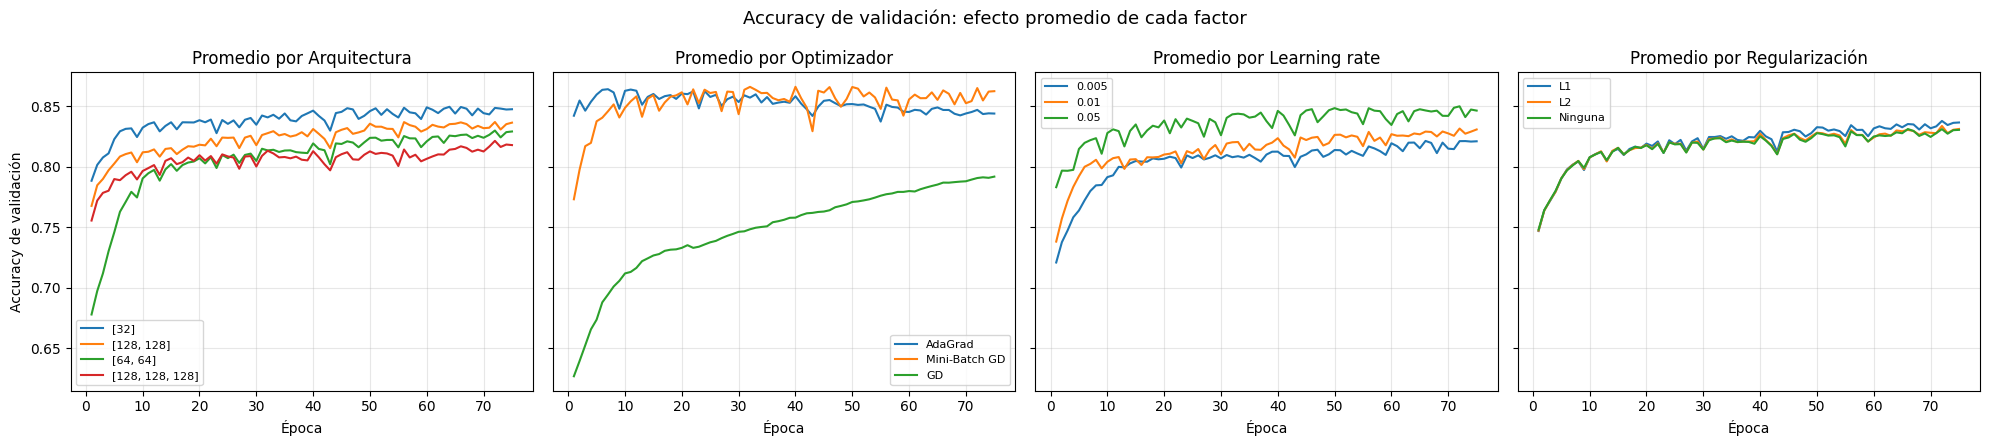

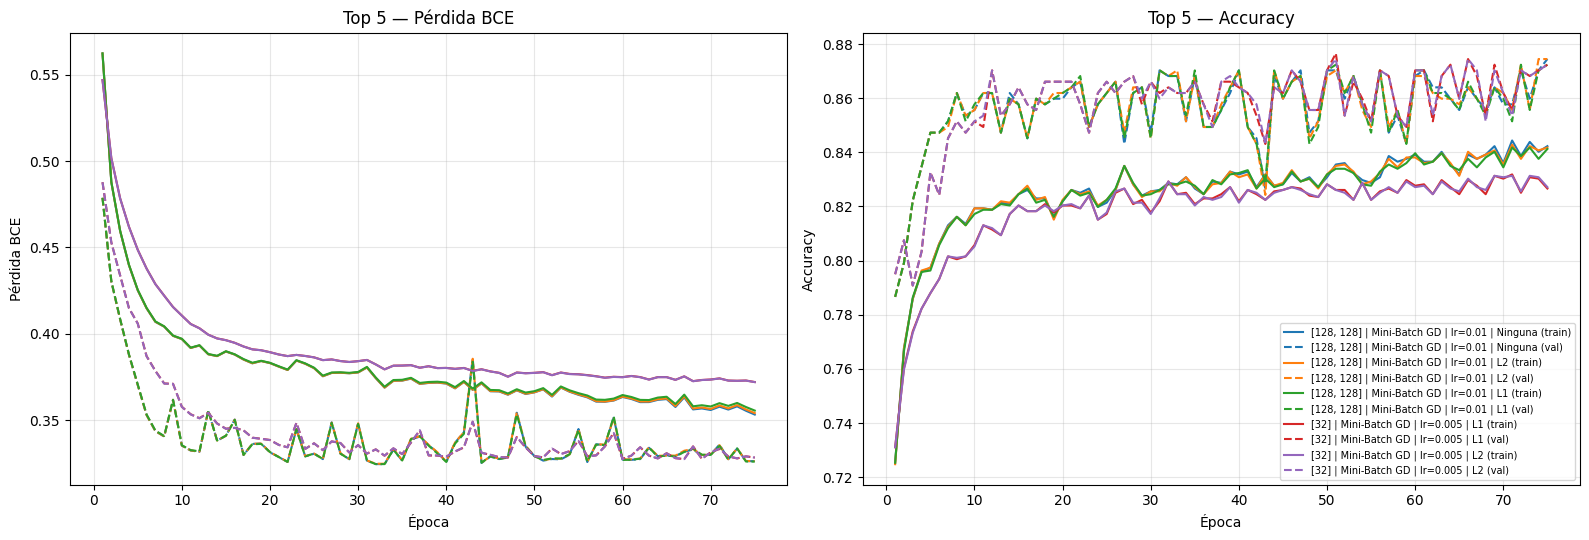

In [34]:
# ============================================================
# GRÁFICAS DE PÉRDIDA Y ACCURACY POR ÉPOCA
# ============================================================
import matplotlib.pyplot as plt

epocas = range(1, FINAL_EPOCHS + 1)
colores_reg = {"L1": "tab:blue", "L2": "tab:orange", "Ninguna": "tab:green"}


def graficar_grilla(metrica, etiqueta_y):
    """
    Una figura por arquitectura. Filas = optimizador, columnas = learning rate.
    En cada panel: entrenamiento (línea continua) y validación (discontinua)
    para L1 y L2.
    """
    for arch_name in final_architectures:
        fig, axes = plt.subplots(
            len(final_optimizers), len(final_learning_rates),
            figsize=(16, 11), sharex=True, sharey="row"
        )
        for i, opt in enumerate(final_optimizers):
            for j, lr in enumerate(final_learning_rates):
                ax = axes[i, j]
                for reg in final_regularizations:
                    h = final_results[(arch_name, opt, lr, reg)]["history"]
                    ax.plot(epocas, h[f"train_{metrica}"], color=colores_reg[reg],
                            linestyle="-", label=f"{reg} - Train")
                    ax.plot(epocas, h[f"val_{metrica}"], color=colores_reg[reg],
                            linestyle="--", label=f"{reg} - Val")
                ax.set_title(f"{opt} | lr = {lr}", fontsize=10)
                ax.grid(True, alpha=0.3)
                if i == len(final_optimizers) - 1:
                    ax.set_xlabel("Época")
                if j == 0:
                    ax.set_ylabel(etiqueta_y)

        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.955))
        fig.suptitle(f"{etiqueta_y} por época — Arquitectura {arch_name}", fontsize=14, y=0.99)
        fig.tight_layout(rect=[0, 0, 1, 0.93])
        plt.show()


# ------------------------------------------------------------
# 1. Curvas de pérdida (BCE) de las 108 combinaciones
# ------------------------------------------------------------
graficar_grilla("loss", "Pérdida BCE")

# ------------------------------------------------------------
# 2. Curvas de accuracy de las 108 combinaciones
# ------------------------------------------------------------
graficar_grilla("accuracy", "Accuracy")

# ------------------------------------------------------------
# 3. Curva promedio de validación por nivel de cada factor
# ------------------------------------------------------------
factores = {
    "Arquitectura": (0, list(final_architectures.keys())),
    "Optimizador": (1, final_optimizers),
    "Learning rate": (2, final_learning_rates),
    "Regularización": (3, final_regularizations),
}

for metrica, etiqueta_y in [("val_loss", "Pérdida BCE de validación"),
                            ("val_accuracy", "Accuracy de validación")]:
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
    for ax, (nombre_factor, (pos, niveles)) in zip(axes, factores.items()):
        for nivel in niveles:
            curvas = [res["history"][metrica] for clave, res in final_results.items() if clave[pos] == nivel]
            media = np.mean(curvas, axis=0)
            ax.plot(epocas, media, label=str(nivel))
        ax.set_title(f"Promedio por {nombre_factor}")
        ax.set_xlabel("Época")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    axes[0].set_ylabel(etiqueta_y)
    fig.suptitle(f"{etiqueta_y}: efecto promedio de cada factor", fontsize=13)
    fig.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 4. Top 5 configuraciones (según validación)
# ------------------------------------------------------------
top5 = final_df_ordenado.head(5)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for _, fila in top5.iterrows():
    clave = (fila["arquitectura"], fila["optimizador"], fila["learning_rate"], fila["regularizacion"])
    h = final_results[clave]["history"]
    nombre = f"{clave[0]} | {clave[1]} | lr={clave[2]} | {clave[3]}"
    linea, = axes[0].plot(epocas, h["train_loss"], label=f"{nombre} (train)")
    axes[0].plot(epocas, h["val_loss"], linestyle="--", color=linea.get_color(), label=f"{nombre} (val)")
    axes[1].plot(epocas, h["train_accuracy"], color=linea.get_color(), label=f"{nombre} (train)")
    axes[1].plot(epocas, h["val_accuracy"], linestyle="--", color=linea.get_color(), label=f"{nombre} (val)")

axes[0].set_title("Top 5 — Pérdida BCE")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida BCE"); axes[0].grid(True, alpha=0.3)
axes[1].set_title("Top 5 — Accuracy")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy"); axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()


Mejor configuración según validación:
  Arquitectura:   [128, 128]
  Optimizador:    Mini-Batch GD
  Learning rate:  0.01
  Pérdida:        BCE
  Regularización: Ninguna
  Épocas:         75

  Val acc: 0.8745 | Val loss: 0.3262
  Test acc: 0.8047 | Test F1: 0.7167 | Test recall: 0.6916 | Test AUC: 0.8949 | Test loss: 0.3900

Reporte de clasificación en el conjunto de prueba:
              precision    recall  f1-score   support

           0     0.8350    0.8675    0.8510       385
           1     0.7437    0.6916    0.7167       214

    accuracy                         0.8047       599
   macro avg     0.7894    0.7796    0.7838       599
weighted avg     0.8024    0.8047    0.8030       599



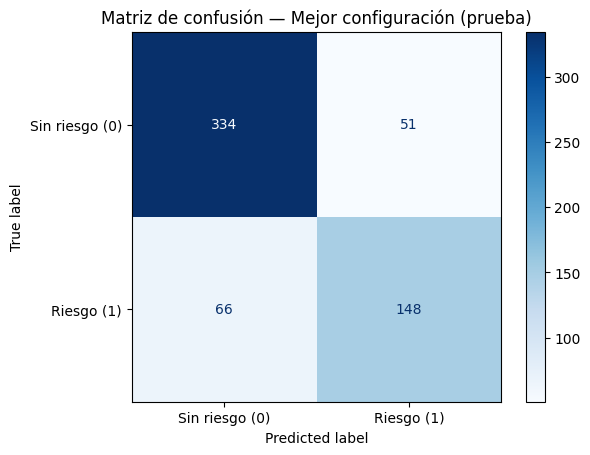

In [35]:
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score, recall_score, roc_auc_score
import matplotlib.pyplot as plt

mejor = final_df_ordenado.iloc[0]
clave_mejor = (mejor["arquitectura"], mejor["optimizador"], mejor["learning_rate"], mejor["regularizacion"])
modelo_mejor = final_results[clave_mejor]["model"]

# Evaluate on the test set for the best model to get the missing metrics
modelo_mejor.eval()
with torch.no_grad():
    test_logits = modelo_mejor(X_test_tensor)
    test_proba_tensor = torch.sigmoid(test_logits)
    test_pred_tensor = (test_proba_tensor >= 0.5).int()

# Convert to numpy for sklearn metrics
y_test_np = y_test  # y_test is already numpy array from kernel state
test_proba_np = test_proba_tensor.view(-1).numpy()
test_pred_np = test_pred_tensor.view(-1).numpy()

# Calculate metrics
test_acc = accuracy_score(y_test_np, test_pred_np)
test_f1 = f1_score(y_test_np, test_pred_np)
test_recall = recall_score(y_test_np, test_pred_np)
test_auc = roc_auc_score(y_test_np, test_proba_np)

# Calculate test loss
criterion = nn.BCEWithLogitsLoss()
test_loss = criterion(test_logits, y_test_tensor).item()

print("Mejor configuración según validación:")
print(f"  Arquitectura:   {clave_mejor[0]}")
print(f"  Optimizador:    {clave_mejor[1]}")
print(f"  Learning rate:  {clave_mejor[2]}")
print(f"  Pérdida:        {final_loss}")
print(f"  Regularización: {clave_mejor[3]}")
print(f"  Épocas:         {FINAL_EPOCHS}")
print(f"\n  Val acc: {mejor['val_acc']:.4f} | Val loss: {mejor['val_loss']:.4f}")
print(f"  Test acc: {test_acc:.4f} | Test F1: {test_f1:.4f} | "
      f"Test recall: {test_recall:.4f} | Test AUC: {test_auc:.4f} | Test loss: {test_loss:.4f}")

modelo_mejor.eval()
with torch.no_grad():
    pred_mejor = (torch.sigmoid(modelo_mejor(X_test_tensor)) >= 0.5).int().view(-1).numpy()

print("\nReporte de clasificación en el conjunto de prueba:")
print(classification_report(y_test, pred_mejor, digits=4))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_mejor, display_labels=["Sin riesgo (0)", "Riesgo (1)"], cmap="Blues"
)
plt.title("Matriz de confusión — Mejor configuración (prueba)")
plt.show()